# Khám phá dữ liệu League of Legends — Season 15 (EUN)

## Mục tiêu và phạm vi

kiểm tra chất lượng, mô tả phân bố và
khám phá mối liên hệ trong **Rank, Thông thạo (Mastery), Vị trí, Tướng, Mục tiêu lớn
và công trình**.

**Đơn vị quan sát:** một dòng CSV là một lượt người chơi–trận. Các bảng mục tiêu
được chuyển thành đội–trận, sau đó ghép hai đội để phân tích trận.
Không có mã tài khoản bền vững để đếm người chơi duy nhất.

Mỗi mục gồm mục đích, code, bảng/biểu đồ và nhận xét tính từ dữ liệu đang chạy.
Tỷ lệ dùng mẫu nào được ghi ngay bên cạnh bảng hoặc biểu đồ. Đọc lần lượt từ trên
xuống.

## 1. Đọc và kiểm tra dữ liệu

Giữ nguyên CSV trong `df_raw`; 24 cột (5 nhóm được giao) trong `df`; bỏ hai cột chữ
Flex(2 cột bị nhiều nhiều) khỏi `df_kham_pha`. Bảng `eda_df` bổ sung khóa và thông tin hỗ trợ từ chính
`df_raw` theo cùng chỉ mục, sau khi kiểm tra khóa. Ba cột số Flex vẫn được giữ.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [2]:
# Giữ phong cách xanh ngọc; cỡ chữ đủ đọc trong notebook và khi xuất hình.
TEAL = '#087F78'
TEAL_LIGHT = '#8FD0C7'
TEAL_COLORS = ['#CDEAE6', '#8FD0C7', '#43AAA0', '#087F78']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'figure.dpi': 110, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.axisbelow': True,
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

tier_order_all = [
    'IRON', 'BRONZE', 'SILVER', 'GOLD', 'PLATINUM',
    'EMERALD', 'DIAMOND', 'MASTER', 'GRANDMASTER', 'CHALLENGER'
]
tier_order_divisions = tier_order_all[:7]
division_order = ['IV', 'III', 'II', 'I']
position_order = ['TOP', 'JUNGLE', 'MIDDLE', 'BOTTOM', 'SUPPORT']
rank_cols = ['solo_tier', 'solo_rank', 'solo_lp', 'solo_wins', 'solo_losses']
mastery_cols = [
    'mastery_level', 'mastery_points', 'mastery_lastPlayTime',
    'mastery_pointsSinceLastLevel', 'mastery_pointsUntilNextLevel', 'mastery_tokens'
]
objective_cols = [
    'team_baronKills', 'team_dragonKills', 'team_riftHeraldKills',
    'team_towerKills', 'team_inhibitorKills'
]
objective_labels = {
    'team_baronKills': 'Baron', 'team_dragonKills': 'Rồng',
    'team_riftHeraldKills': 'Sứ Giả', 'team_towerKills': 'Trụ',
    'team_inhibitorKills': 'Nhà lính'
}

# Nhãn tiếng Việt chỉ dùng khi hiển thị hoặc xuất bảng.
# Các DataFrame dùng để tính toán vẫn giữ tên cột gốc.
nhan_bang = {
    'so_o_thieu': 'Số ô thiếu',
    'ty_le_thieu_pct': 'Tỷ lệ thiếu (%)',
    'kieu_du_lieu': 'Kiểu dữ liệu',
    'so_gia_tri_khac_nhau': 'Số giá trị khác nhau',
    'so_gia_tri_am': 'Số giá trị âm',
    'so_gia_tri_0': 'Số giá trị bằng 0',
    'ty_le_0_pct': 'Tỷ lệ bằng 0 (%)',
    'so_0_trong_nhom_thieu_rank': 'Số giá trị 0 trong nhóm thiếu Rank',
    'so_luot': 'Số lượt',
    'tong_luot': 'Tổng số lượt',
    'tong_luot_hop_le': 'Tổng số lượt hợp lệ',
    'ty_trong_pct': 'Tỷ trọng (%)',
    'ty_trong_tren_toan_bo_pct': 'Tỷ trọng trên toàn bộ dữ liệu (%)',
    'so_tran': 'Số trận',
    'ty_trong_tran_pct': 'Tỷ trọng số trận (%)',
    'trung_binh': 'Trung bình',
    'trung_vi': 'Trung vị',
    'nho_nhat': 'Nhỏ nhất',
    'lon_nhat': 'Lớn nhất',
    'q25': 'Q1 (25%)',
    'q75': 'Q3 (75%)',
    'count': 'Số quan sát',
    'size': 'Số quan sát',
    'mean': 'Trung bình',
    'median': 'Trung vị',
    'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất',
    'max': 'Lớn nhất',
    '25%': 'Q1 (25%)',
    '50%': 'Trung vị (50%)',
    '75%': 'Q3 (75%)',
    '90%': 'P90 (90%)',
    '95%': 'P95 (95%)',
    '99%': 'P99 (99%)',
    'solo_tier': 'Bậc Rank Solo/Duo',
    'solo_rank': 'Đoàn Solo/Duo',
    'solo_lp': 'Điểm LP Solo/Duo',
    'solo_wins': 'Số trận thắng Solo/Duo',
    'solo_losses': 'Số trận thua Solo/Duo',
    'flex_tier': 'Bậc Rank Flex',
    'flex_rank': 'Đoàn Flex',
    'flex_lp': 'Điểm LP Flex',
    'flex_wins': 'Số trận thắng Flex',
    'flex_losses': 'Số trận thua Flex',
    'solo_total_games': 'Tổng số trận đã chơi',
    'account_win_rate_pct': 'Tỷ lệ thắng tài khoản (%)',
    'trung_vi_tong_tran': 'Trung vị tổng số trận đã chơi',
    'trung_vi_ty_le_thang_pct': 'Trung vị tỷ lệ thắng (%)',
    'mastery_level': 'Cấp thông thạo',
    'mastery_points': 'Điểm thông thạo',
    'mastery_lastPlayTime': 'Thời điểm chơi gần nhất (ms)',
    'mastery_pointsSinceLastLevel': 'Điểm từ cấp gần nhất',
    'mastery_pointsUntilNextLevel': 'Điểm tới cấp kế tiếp',
    'mastery_tokens': 'Số token thông thạo',
    'ty_le_diem_0_pct': 'Tỷ lệ điểm bằng 0 (%)',
    'moc': 'Mốc thời gian',
    'UTC': 'Thời gian (UTC)',
    'position': 'Vị trí',
    'position_before': 'Vị trí ban đầu',
    'position_after': 'Vị trí đã sửa',
    'raw_invalid_position_rows': 'Số lượt có vị trí không hợp lệ ban đầu',
    'corrected_position_rows': 'Số lượt đã sửa vị trí',
    'position_corrections_exactly_three': 'Đã sửa đúng ba dòng vị trí',
    'champion_id': 'Mã tướng',
    'champion_name': 'Tên tướng',
    'game_id': 'Mã trận',
    'participant_id': 'Mã người tham gia trong trận',
    'win': 'Nhóm đội',
    'duration': 'Thời lượng (giây)',
    'duration_min': 'Thời lượng (phút)',
    'duration_group': 'Nhóm thời lượng (phút)',
    'start_utc': 'Thời điểm bắt đầu (UTC)',
    'start_datetime': 'Thời điểm bắt đầu (UTC)',
    'game_version': 'Phiên bản',
    'loai_doi': 'Loại đội',
    'so_doi_tran': 'Số đội–trận',
    'so_tran_co_tuong': 'Số trận có tướng',
    'ty_trong_luot_pct': 'Tỷ trọng lượt xuất hiện (%)',
    'ty_le_tran_co_tuong_pct': 'Tỷ lệ trận có tướng (%)',
    'team_baronKills': 'Số Baron của đội',
    'team_dragonKills': 'Số rồng của đội',
    'team_riftHeraldKills': 'Số Sứ Giả của đội',
    'team_towerKills': 'Số trụ phá của đội',
    'team_inhibitorKills': 'Số lần phá nhà lính của đội',
    'so_doi_co_gia_tri_khong_nhat_quan': 'Số đội có dữ liệu không nhất quán',
    'tong_sai_neu_cong_moi_luot': 'Tổng bị đếm lặp theo lượt',
    'tong_dung_cap_doi_tran': 'Tổng đúng theo đội–trận',
    'he_so_dem_lap': 'Hệ số đếm lặp',
    'ty_le_doi_khong_co_muc_tieu_pct': 'Tỷ lệ đội không có mục tiêu (%)',
    'phut_tran': 'Thời lượng trận (phút)',
    'chenh_lech_trung_vi': 'Trung vị chênh lệch',
    'thang_nhieu_hon_pct': 'Đội thắng nhiều hơn (%)',
    'bang_nhau_pct': 'Bằng nhau (%)',
    'thang_it_hon_pct': 'Đội thắng ít hơn (%)',
    'so_sanh': 'So sánh với đối thủ',
    'muc_tieu': 'Mục tiêu',
    'doi_thang_trung_binh': 'Đội thắng (trung bình)',
    'doi_thua_trung_binh': 'Đội thua (trung bình)',
    'chenh_lech_thang_thua': 'Chênh lệch (thắng − thua)',
    'so_thang': 'Số đội thắng',
    'ty_le_thang_pct': 'Tỷ lệ thắng (%)',
    'so_luot_cua_bac': 'Số lượt của bậc',
    'tuong_nhieu_luot_nhat': 'Tướng phổ biến nhất',
    'so_luot_tuong_dung_dau': 'Số lượt của tướng đứng đầu',
    'ty_trong_tuong_dung_dau_pct': 'Tỷ trọng tướng đứng đầu (%)',
    'ket_qua': 'Kết quả',
    'raw_rows': 'Số dòng dữ liệu gốc',
    'raw_columns': 'Số cột dữ liệu gốc',
    'games': 'Số trận',
    'team_rows': 'Số đội–trận',
    'original_selection_columns': 'Số cột chọn ban đầu',
    'exploration_columns': 'Số cột khám phá',
    'full_duplicate_rows': 'Số dòng trùng hoàn toàn',
    'duplicate_participant_keys': 'Số khóa người chơi–trận bị trùng',
    'all_games_have_10_rows': 'Mọi trận đều có 10 lượt',
    'all_teams_have_5_rows': 'Mọi đội đều có 5 lượt',
    'rank_distribution_sums_to_rows': 'Tổng số lượt theo Rank khớp dữ liệu',
    'division_rows_are_iron_to_diamond': 'Bảng đoàn chỉ gồm Iron–Diamond',
    'division_rows_sum_to_100': 'Tổng tỷ lệ đoàn mỗi bậc bằng 100%',
    'all_numeric_flex_columns_retained': 'Giữ đủ ba cột số Flex',
    'champion_mapping_one_to_one': 'Mã và tên tướng khớp một-một',
    'champion_counts_sum_to_rows': 'Tổng số lượt theo tướng khớp dữ liệu',
    'champion_position_rows_sum_to_100': 'Tổng tỷ lệ vị trí mỗi tướng bằng 100%',
    'team_objectives_constant': 'Mục tiêu nhất quán trong mỗi đội',
    'two_team_rows_per_game': 'Mỗi trận có hai dòng đội–trận',
    'paired_deltas_equal_game_count': 'Số cặp chênh lệch khớp số trận',
    'objective_totals_not_repeated': 'Tổng mục tiêu tránh đếm lặp 5 lần',
    'duration_groups_cover_all_games': 'Nhóm thời lượng bao phủ mọi trận',
    'duration_unit_seconds_checked': 'Đã kiểm tra thời lượng theo giây',
    'source_csv_unchanged': 'CSV gốc giữ nguyên',
    'rank_missing_rows': 'Số lượt thiếu Rank',
    'all_zero_mastery_rows': 'Số lượt có mọi trường Mastery bằng 0',
    'invalid_position_rows': 'Số lượt có vị trí không hợp lệ',
    'teams_without_one_of_each_position': 'Số đội có cơ cấu vị trí cần kiểm tra',
}


def bang_tieng_viet(bang):
    """Tạo bản trình bày có dấu; không đổi bảng dùng tính toán."""
    if isinstance(bang, pd.Series):
        bang = bang.to_frame()
    bang_hien_thi = bang.copy()
    # Chỉ đổi đúng trường win; True/False của các phép kiểm tra vẫn giữ nguyên.
    nhom_doi = {True: 'Thắng', False: 'Thua'}
    if 'win' in bang_hien_thi.columns:
        bang_hien_thi['win'] = bang_hien_thi['win'].map(nhom_doi)
    if 'win' in bang_hien_thi.index.names:
        bang_hien_thi = bang_hien_thi.rename(index=nhom_doi, level='win')
    bang_hien_thi = bang_hien_thi.rename(columns=nhan_bang, index=nhan_bang)
    return bang_hien_thi.rename_axis(
        index=[nhan_bang.get(ten, ten) for ten in bang.index.names],
        columns=[nhan_bang.get(ten, ten) for ten in bang.columns.names]
    )


In [3]:
csv_path = Path('data') / 'League of Legends Ranked Match Data  Season 15 (EUN).csv'
if not csv_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy {csv_path.resolve()}. Mở notebook từ thư mục dự án.')

csv_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
df_raw = pd.read_csv(csv_path)
original_cols = (
    rank_cols + ['flex_tier', 'flex_rank', 'flex_lp', 'flex_wins', 'flex_losses']
    + mastery_cols + ['position', 'champion_id', 'champion_name'] + objective_cols
)
support_cols = ['game_id', 'participant_id', 'win', 'duration', 'start_utc', 'game_version']
required_cols = original_cols + support_cols
assert set(required_cols).issubset(df_raw.columns), 'CSV thiếu cột cần cho EDA.'

df = df_raw[original_cols].copy()
df_kham_pha = df.drop(columns=['flex_tier', 'flex_rank']).copy()
assert not df_raw[['game_id', 'participant_id']].isna().any().any(), 'Khóa bị thiếu.'
assert not df_raw.duplicated(['game_id', 'participant_id']).any(), 'Khóa người chơi–trận bị trùng.'
# Cùng nguồn và cùng chỉ mục nên không cần merge có nguy cơ nhân bản dòng.
eda_df = df_kham_pha.join(df_raw[support_cols]).copy()
assert eda_df['win'].notna().all() and eda_df['win'].isin([True, False]).all()
eda_df['win'] = eda_df['win'].astype(bool)

# Sửa đúng ba dòng theo yêu cầu; xác định đội bằng game_id + win đã kiểm tra.
position_fixes = [
    (3745901996, 10, 'Yuumi', 'SUPPORT'),
    (3745423855, 6, 'Volibear', None),
    (3741617085, 5, 'Lulu', 'SUPPORT'),
]
position_correction_records = []
raw_invalid_position_count = int((~df_raw['position'].isin(position_order)).sum())
for game_id, participant_id, champion, new_position in position_fixes:
    player_mask = eda_df['game_id'].eq(game_id) & eda_df['participant_id'].eq(participant_id)
    assert player_mask.sum() == 1, 'Không tìm thấy duy nhất dòng cần sửa.'
    player_index = eda_df.index[player_mask][0]
    player = eda_df.loc[player_index]
    assert player['champion_name'] == champion, 'Tên tướng không khớp khóa cần sửa.'
    teammates = eda_df.loc[
        eda_df['game_id'].eq(game_id) & eda_df['win'].eq(player['win']) & ~player_mask
    ]
    assert len(teammates) == 4, 'Cần xác minh lại đội của dòng cần sửa.'
    missing_positions = set(position_order) - set(teammates['position'])
    if champion == 'Volibear':
        assert len(missing_positions) == 1 and missing_positions.issubset({'TOP', 'JUNGLE'})
        new_position = next(iter(missing_positions))
    assert missing_positions == {new_position}, 'Vị trí được gán không khớp vị trí còn thiếu.'
    assert df_raw.at[player_index, 'position'] == 'Invalid', 'Nhãn gốc của dòng đã thay đổi.'
    position_correction_records.append({
        'game_id': game_id, 'participant_id': participant_id, 'champion_name': champion,
        'position_before': df_raw.at[player_index, 'position'], 'position_after': new_position
    })
    # Đồng bộ các bảng phân tích, không sửa df_raw hoặc tệp CSV gốc.
    for analysis_table in [df, df_kham_pha, eda_df]:
        analysis_table.at[player_index, 'position'] = new_position

position_corrections = pd.DataFrame(position_correction_records)
assert len(position_corrections) == 3
assert eda_df['position'].ne(df_raw['position']).sum() == 3
assert eda_df.loc[eda_df['champion_name'].eq('Volibear') & eda_df['game_id'].eq(3745423855), 'position'].eq('TOP').all()

print('CSV gốc:', df_raw.shape, '| df:', df.shape, '| df_kham_pha:', df_kham_pha.shape)
display(bang_tieng_viet(df.head()))



CSV gốc: (68300, 69) | df: (68300, 24) | df_kham_pha: (68300, 22)


,Bậc Rank Solo/Duo,Đoàn Solo/Duo,Điểm LP Solo/Duo,Số trận thắng Solo/Duo,Số trận thua Solo/Duo,Bậc Rank Flex,Đoàn Flex,Điểm LP Flex,Số trận thắng Flex,Số trận thua Flex,Cấp thông thạo,Điểm thông thạo,Thời điểm chơi gần nhất (ms),Điểm từ cấp gần nhất,Điểm tới cấp kế tiếp,Số token thông thạo,Vị trí,Mã tướng,Tên tướng,Số Baron của đội,Số rồng của đội,Số Sứ Giả của đội,Số trụ phá của đội,Số lần phá nhà lính của đội
0,GOLD,I,13,40,34,NaN,NaN,0,0,0,31,357243,1740012134000,50643,0,0,TOP,266,Aatrox,0,4,0,10,4
1,PLATINUM,IV,65,101,103,NaN,NaN,0,0,0,4,20196,1740012134000,7596,1404,2,JUNGLE,141,Kayn,0,4,0,10,4
2,PLATINUM,IV,64,40,35,NaN,NaN,0,0,0,17,191886,1740012134000,39286,0,0,MIDDLE,99,Lux,0,4,0,10,4
3,PLATINUM,IV,54,37,29,NaN,NaN,0,0,0,4,15064,1740012134000,2464,6536,1,BOTTOM,110,Varus,0,4,0,10,4
4,PLATINUM,IV,49,66,52,NaN,NaN,0,0,0,40,412853,1740012134000,7253,3747,0,SUPPORT,412,Thresh,0,4,0,10,4


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 68300 entries, 0 to 68299
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   solo_tier                     67626 non-null  str  
 1   solo_rank                     67626 non-null  str  
 2   solo_lp                       68300 non-null  int64
 3   solo_wins                     68300 non-null  int64
 4   solo_losses                   68300 non-null  int64
 5   flex_tier                     27705 non-null  str  
 6   flex_rank                     27705 non-null  str  
 7   flex_lp                       68300 non-null  int64
 8   flex_wins                     68300 non-null  int64
 9   flex_losses                   68300 non-null  int64
 10  mastery_level                 68300 non-null  int64
 11  mastery_points                68300 non-null  int64
 12  mastery_lastPlayTime          68300 non-null  int64
 13  mastery_pointsSinceLastLevel  68300 non-nu

### 1.1. Khóa, cấu trúc trận và chất lượng chung

`isna()` phát hiện ô thiếu; `duplicated()` kiểm tra trùng; `groupby()` chia dữ liệu
thành nhóm để kiểm tra từng trận/đội. Không tự xóa dòng hoặc điền thiếu.


In [5]:
quality_summary = pd.DataFrame({
    'kieu_du_lieu': eda_df.dtypes.astype(str),
    'so_o_thieu': eda_df.isna().sum(),
    'ty_le_thieu_pct': eda_df.isna().mean() * 100,
    'so_gia_tri_khac_nhau': eda_df.nunique(dropna=True)
})
display(bang_tieng_viet(quality_summary))

game_sizes = eda_df.groupby('game_id').size()
team_sizes = eda_df.groupby(['game_id', 'win']).size()
outcomes_per_game = eda_df.groupby('game_id')['win'].nunique()
assert game_sizes.eq(10).all(), 'Có trận không đủ 10 lượt.'
assert team_sizes.eq(5).all() and outcomes_per_game.eq(2).all(), 'Không xác nhận được hai đội 5 người.'
assert eda_df.groupby('game_id')['participant_id'].nunique().eq(10).all()
assert eda_df.groupby('game_id')['duration'].nunique(dropna=False).eq(1).all()
assert eda_df['duration'].notna().all() and eda_df['duration'].gt(0).all()
assert eda_df.groupby('game_id')['start_utc'].nunique(dropna=False).eq(1).all()
assert eda_df.groupby('game_id')['game_version'].nunique(dropna=False).eq(1).all()

# Kiểm tra đơn vị duration bằng quan hệ với chỉ số mỗi phút có sẵn trong CSV.
duration_is_seconds = np.allclose(
    df_raw['gold_earned'] / (df_raw['duration'] / 60), df_raw['gold_per_min']
)
assert duration_is_seconds, 'Cần xác minh lại đơn vị duration.'
eda_df['duration_min'] = eda_df['duration'] / 60
eda_df['start_datetime'] = pd.to_datetime(eda_df['start_utc'], utc=True, errors='coerce')
assert eda_df['start_datetime'].notna().all()
n_rows = len(eda_df)
n_games = eda_df['game_id'].nunique()
version_summary = eda_df.groupby('game_version')['game_id'].nunique().sort_values(ascending=False).rename('so_tran').to_frame()
version_summary['ty_trong_tran_pct'] = version_summary['so_tran'] / n_games * 100
display(bang_tieng_viet(version_summary))
duplicate_rows = int(df_raw.duplicated().sum())
flex_missing = df[['flex_tier', 'flex_rank']].isna().mean() * 100
display(Markdown(f"""
**Nhận xét:** CSV có **{n_rows:,} hàng**, **{df_raw.shape[1]} cột**, **{n_games:,} trận**;
{duplicate_rows} dòng trùng hoàn toàn, không trùng khóa người chơi–trận.
Mỗi trận có đúng 10 hàng, gồm 5 thắng và 5 thua. Queue quan sát được:
{', '.join(df_raw['queue'].dropna().unique())}.
Thời gian trận từ **{eda_df['start_datetime'].min():%d/%m/%Y}** đến
**{eda_df['start_datetime'].max():%d/%m/%Y}** (UTC).
Hai cột chữ Flex thiếu lần lượt {flex_missing['flex_tier']:.2f}% và
{flex_missing['flex_rank']:.2f}%; chỉ bỏ hai cột này khỏi bảng khám phá.
Duration phù hợp đơn vị giây theo kiểm tra chỉ số vàng/phút; đổi sang phút để so sánh.
"""))


,Kiểu dữ liệu,Số ô thiếu,Tỷ lệ thiếu (%),Số giá trị khác nhau
Bậc Rank Solo/Duo,str,674,0.99,10
Đoàn Solo/Duo,str,674,0.99,4
Điểm LP Solo/Duo,int64,0,0.00,700
Số trận thắng Solo/Duo,int64,0,0.00,302
Số trận thua Solo/Duo,int64,0,0.00,299
Điểm LP Flex,int64,0,0.00,174
Số trận thắng Flex,int64,0,0.00,127
Số trận thua Flex,int64,0,0.00,119
Cấp thông thạo,int64,0,0.00,371
Điểm thông thạo,int64,0,0.00,51089


,Số trận,Tỷ trọng số trận (%)
Phiên bản,,
15.3.656.4086,5620,82.28
15.3.654.407,665,9.74
15.4.657.5386,264,3.87
15.2.652.1536,238,3.48
15.1.649.4112,36,0.53
15.1.648.3927,7,0.10



**Nhận xét:** CSV có **68,300 hàng**, **69 cột**, **6,830 trận**;
0 dòng trùng hoàn toàn, không trùng khóa người chơi–trận.
Mỗi trận có đúng 10 hàng, gồm 5 thắng và 5 thua. Queue quan sát được:
Ranked Solo/Duo.
Thời gian trận từ **10/01/2025** đến
**20/02/2025** (UTC).
Hai cột chữ Flex thiếu lần lượt 59.44% và
59.44%; chỉ bỏ hai cột này khỏi bảng khám phá.
Duration phù hợp đơn vị giây theo kiểm tra chỉ số vàng/phút; đổi sang phút để so sánh.


## 2. Khám phá nhóm xếp hạng

### 2.1. Thiếu dữ liệu và phân bố bậc
đếm cả nhóm thiếu; nhãn `UNKNOWN` chỉ dùng khi trình bày, không ghi vào dữ liệu gốc.


In [6]:
rank_df = df_kham_pha[rank_cols].copy()
display(bang_tieng_viet(rank_df.head()))
rank_df.info()
missing_summary = pd.DataFrame({
    'so_o_thieu': rank_df.isna().sum(),
    'ty_le_thieu_pct': rank_df.isna().mean() * 100
})
display(bang_tieng_viet(missing_summary.round(2)))
display(bang_tieng_viet(rank_df['solo_tier'].value_counts(dropna=False).rename('so_luot')))
display(bang_tieng_viet(rank_df['solo_rank'].value_counts(dropna=False).rename('so_luot')))

rank_missing_mask = rank_df[['solo_tier', 'solo_rank']].isna().any(axis=1)
rank_numeric_cols = ['solo_lp', 'solo_wins', 'solo_losses']
display(bang_tieng_viet(pd.DataFrame({
    'so_gia_tri_am': rank_df[rank_numeric_cols].lt(0).sum(),
    'so_0_trong_nhom_thieu_rank': rank_df.loc[rank_missing_mask, rank_numeric_cols].eq(0).sum()
})))
assert rank_df['solo_tier'].dropna().isin(tier_order_all).all()
assert rank_df['solo_rank'].dropna().isin(division_order).all()
rank_valid = rank_df.loc[~rank_missing_mask].copy()
display(Markdown(f"""
**Xử lý:** giữ nguyên {rank_missing_mask.sum():,} lượt thiếu bậc/đoàn trong thống kê
tổng thể; loại riêng chúng khỏi thống kê tài khoản theo rank.
Mẫu còn **{len(rank_valid):,} lượt**.
"""))


<class 'pandas.DataFrame'>
RangeIndex: 68300 entries, 0 to 68299
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   solo_tier    67626 non-null  str  
 1   solo_rank    67626 non-null  str  
 2   solo_lp      68300 non-null  int64
 3   solo_wins    68300 non-null  int64
 4   solo_losses  68300 non-null  int64
dtypes: int64(3), str(2)
memory usage: 3.2 MB


,Bậc Rank Solo/Duo,Đoàn Solo/Duo,Điểm LP Solo/Duo,Số trận thắng Solo/Duo,Số trận thua Solo/Duo
0,GOLD,I,13,40,34
1,PLATINUM,IV,65,101,103
2,PLATINUM,IV,64,40,35
3,PLATINUM,IV,54,37,29
4,PLATINUM,IV,49,66,52


,Số ô thiếu,Tỷ lệ thiếu (%)
Bậc Rank Solo/Duo,674,0.99
Đoàn Solo/Duo,674,0.99
Điểm LP Solo/Duo,0,0.00
Số trận thắng Solo/Duo,0,0.00
Số trận thua Solo/Duo,0,0.00


,Số lượt
Bậc Rank Solo/Duo,
EMERALD,23974
PLATINUM,16480
GOLD,10022
DIAMOND,9667
MASTER,3491
SILVER,2354
GRANDMASTER,897
NaN,674
CHALLENGER,416


,Số lượt
Đoàn Solo/Duo,
IV,21345
III,15871
I,15279
II,15131
NaN,674


,Số giá trị âm,Số giá trị 0 trong nhóm thiếu Rank
Điểm LP Solo/Duo,0,674
Số trận thắng Solo/Duo,0,674
Số trận thua Solo/Duo,0,674



**Xử lý:** giữ nguyên 674 lượt thiếu bậc/đoàn trong thống kê
tổng thể; loại riêng chúng khỏi thống kê tài khoản theo rank.
Mẫu còn **67,626 lượt**.


,Số lượt,Tỷ trọng (%)
Bậc Rank Solo/Duo,,
IRON,15,0.02
BRONZE,310,0.45
SILVER,2354,3.45
GOLD,10022,14.67
PLATINUM,16480,24.13
EMERALD,23974,35.10
DIAMOND,9667,14.15
MASTER,3491,5.11
GRANDMASTER,897,1.31


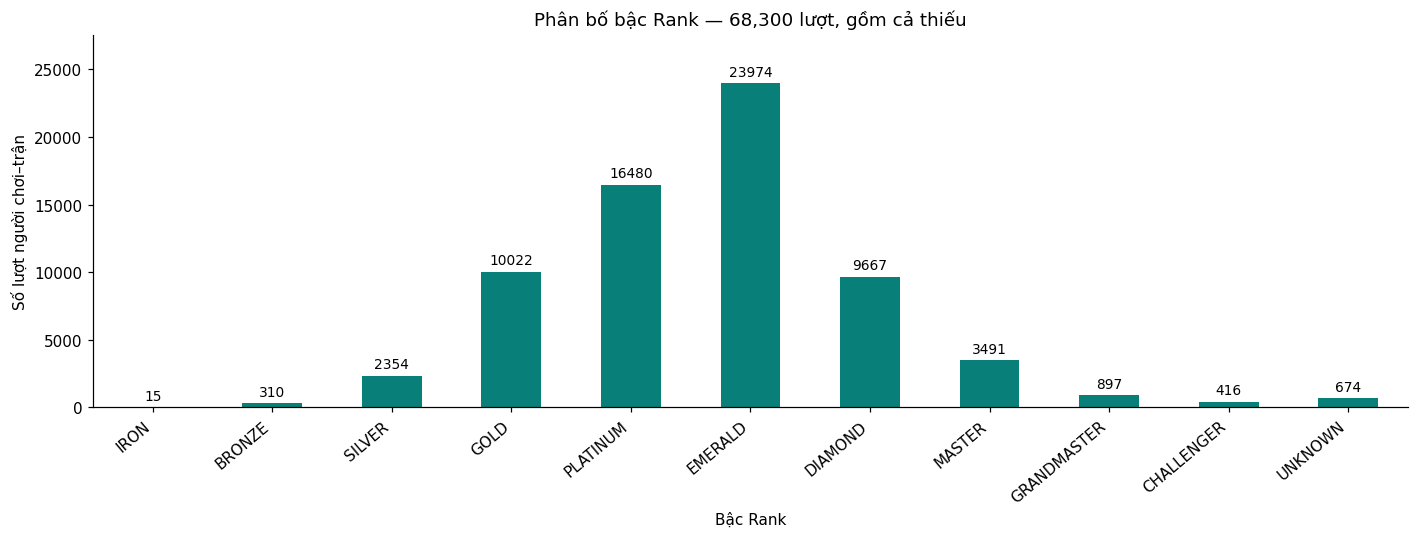


**Nhận xét:** EMERALD có 23,974 lượt
(35.10%), tiếp theo là
PLATINUM với 16,480 lượt
(24.13%). Hai bậc chiếm
**59.23%** toàn bộ lượt.
IRON chỉ có 15 lượt nên so sánh nhóm này dễ biến động.
UNKNOWN có 674 lượt (0.99%).
Phân bố mẫu không cân bằng và không đại diện trực tiếp cho số tài khoản riêng biệt
hay toàn bộ cộng đồng.


In [7]:
tier_counts = (
    rank_df['solo_tier'].fillna('UNKNOWN').value_counts()
    .reindex(tier_order_all + ['UNKNOWN'], fill_value=0)
)
tier_summary = pd.DataFrame({
    'so_luot': tier_counts, 'ty_trong_pct': tier_counts / n_rows * 100
})
display(bang_tieng_viet(tier_summary.round(2)))
ax = tier_counts.plot(kind='bar', figsize=(13, 5), color=TEAL)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set(title=f'Phân bố bậc Rank — {n_rows:,} lượt, gồm cả thiếu',
       xlabel='Bậc Rank', ylabel='Số lượt người chơi–trận')
ax.set_ylim(0, tier_counts.max() * 1.15)
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

top_two_tiers = tier_counts.drop('UNKNOWN').nlargest(2)
display(Markdown(f"""
**Nhận xét:** {top_two_tiers.index[0]} có {top_two_tiers.iloc[0]:,} lượt
({top_two_tiers.iloc[0] / n_rows * 100:.2f}%), tiếp theo là
{top_two_tiers.index[1]} với {top_two_tiers.iloc[1]:,} lượt
({top_two_tiers.iloc[1] / n_rows * 100:.2f}%). Hai bậc chiếm
**{top_two_tiers.sum() / n_rows * 100:.2f}%** toàn bộ lượt.
IRON chỉ có {tier_counts['IRON']:,} lượt nên so sánh nhóm này dễ biến động.
UNKNOWN có {tier_counts['UNKNOWN']:,} lượt ({tier_summary.loc['UNKNOWN', 'ty_trong_pct']:.2f}%).
Phân bố mẫu không cân bằng và không đại diện trực tiếp cho số tài khoản riêng biệt
hay toàn bộ cộng đồng.
"""))


### 2.2. Cơ cấu đoàn trong từng bậc Iron–Diamond

 tổng tỷ lệ mỗi bậc bằng 100%. Bảng số đếm đi kèm cho biết quy mô mẫu.
Không thêm UNKNOWN thành hàng toàn 0 và không vẽ bậc không có quan sát.


Đoàn được ghi nhận ở các bậc cao:
CHALLENGER: I
GRANDMASTER: I
MASTER: I


Đoàn Solo/Duo,IV,III,II,I,Tổng số lượt
Bậc Rank Solo/Duo,,,,,
IRON,0,2,7,6,15
BRONZE,33,59,93,125,310
SILVER,353,551,729,721,2354
GOLD,2556,2303,2871,2292,10022
PLATINUM,5212,4126,4078,3064,16480
EMERALD,8228,6565,5892,3289,23974
DIAMOND,4963,2265,1461,978,9667


Đoàn Solo/Duo,IV,III,II,I
Bậc Rank Solo/Duo,,,,
IRON,0.00,13.33,46.67,40.00
BRONZE,10.65,19.03,30.00,40.32
SILVER,15.00,23.41,30.97,30.63
GOLD,25.50,22.98,28.65,22.87
PLATINUM,31.63,25.04,24.75,18.59
EMERALD,34.32,27.38,24.58,13.72
DIAMOND,51.34,23.43,15.11,10.12


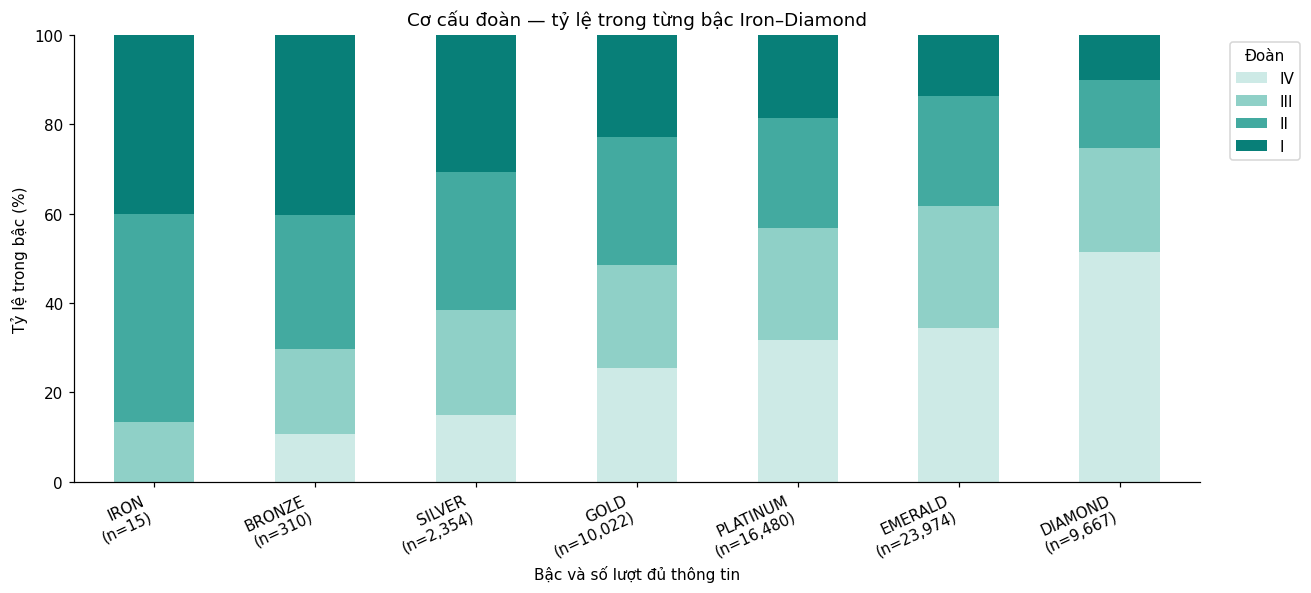


**Nhận xét:** đoàn IV chiếm **51.34%** trong Diamond,
**34.32%** trong Emerald và
**31.63%** trong Platinum.
Iron chỉ có 15 lượt; tỷ lệ cao ở một đoàn của Iron
không có độ ổn định như các bậc nhiều quan sát. Trong tệp này, các bậc Master,
Grandmaster và Challenger chỉ ghi đoàn I nên được mô tả riêng.


In [8]:
division_sample = rank_valid[rank_valid['solo_tier'].isin(tier_order_divisions)]
division_counts = pd.crosstab(division_sample['solo_tier'], division_sample['solo_rank'])
division_counts = division_counts.reindex(
    index=tier_order_divisions, columns=division_order, fill_value=0
)
division_counts = division_counts.loc[division_counts.sum(axis=1).gt(0)]
division_pct = pd.crosstab(
    division_sample['solo_tier'], division_sample['solo_rank'], normalize='index'
).reindex(index=division_counts.index, columns=division_order, fill_value=0) * 100
display(bang_tieng_viet(division_counts.assign(tong_luot=division_counts.sum(axis=1))))
display(bang_tieng_viet(division_pct.round(2)))
assert np.allclose(division_pct.sum(axis=1), 100)

ax = division_pct.plot(kind='bar', stacked=True, figsize=(12, 5.5), color=TEAL_COLORS)
ax.set_xticklabels([
    f'{tier}\n(n={int(division_counts.loc[tier].sum()):,})' for tier in division_counts.index
], rotation=25, ha='right')
ax.set(title='Cơ cấu đoàn — tỷ lệ trong từng bậc Iron–Diamond',
       xlabel='Bậc và số lượt đủ thông tin', ylabel='Tỷ lệ trong bậc (%)', ylim=(0, 100))
ax.legend(title='Đoàn', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
apex_divisions = rank_valid[rank_valid['solo_tier'].isin(tier_order_all[7:])].groupby('solo_tier')['solo_rank'].unique()
print('Đoàn được ghi nhận ở các bậc cao:')
for tier, divisions in apex_divisions.items():
    print(f"{tier}: {', '.join(divisions.tolist())}")
display(Markdown(f"""
**Nhận xét:** đoàn IV chiếm **{division_pct.loc['DIAMOND', 'IV']:.2f}%** trong Diamond,
**{division_pct.loc['EMERALD', 'IV']:.2f}%** trong Emerald và
**{division_pct.loc['PLATINUM', 'IV']:.2f}%** trong Platinum.
Iron chỉ có {division_counts.loc['IRON'].sum():,} lượt; tỷ lệ cao ở một đoàn của Iron
không có độ ổn định như các bậc nhiều quan sát. Trong tệp này, các bậc Master,
Grandmaster và Challenger chỉ ghi đoàn I nên được mô tả riêng.
"""))


### 2.3. So sánh số trận đã chơi giữa các bậc Rank

**Câu hỏi:** Người chơi ở Rank cao có chơi nhiều trận hơn không?

Ở đây, số trận đã chơi là tổng số trận thắng và thua của tài khoản được ghi nhận
trong dữ liệu (`solo_wins + solo_losses`), không phải số trận có trong CSV.

Tạo `solo_total_games = solo_wins + solo_losses`. Mỗi boxplot thể hiện
**phân bố tổng số trận tài khoản được ghi nhận** ở một bậc Rank:

- Vạch cam trong hộp là trung vị.
- Hộp xanh trải từ Q1 đến Q3, chứa 50% số liệu ở giữa.
- Râu kéo đến quan sát xa nhất còn trong khoảng Q1 − 1,5×IQR đến Q3 + 1,5×IQR,
  với IQR = Q3 − Q1. Các chấm ngoài râu vẫn được giữ, chưa coi là dữ liệu sai.

`n` dưới mỗi bậc là số lượt đủ thông tin Rank, không phải số tài khoản duy nhất.

Loại riêng các lượt thiếu bậc/đoàn như ở mục 2.1. Chưa xác minh kỳ tích lũy và
thời điểm chụp thống kê tài khoản; không diễn giải đây là số trận cả đời,
số trận đã chơi ở riêng bậc hiện tại hoặc số trận cần để đạt bậc đó.


,Số lượt,Trung bình,Trung vị,Nhỏ nhất,Lớn nhất,Q1 (25%),Q3 (75%)
Bậc Rank Solo/Duo,,,,,,,
IRON,15,11.47,9.00,5,32,6.00,14.50
BRONZE,310,33.08,15.00,5,240,10.00,34.75
SILVER,2354,74.71,48.00,5,531,21.00,98.00
GOLD,10022,95.86,75.00,5,667,38.00,131.00
PLATINUM,16480,108.03,88.00,5,761,48.00,147.00
EMERALD,23974,117.53,97.00,5,740,55.00,159.00
DIAMOND,9667,134.02,113.00,5,767,68.00,176.00
MASTER,3491,148.73,130.00,23,566,86.00,188.00
GRANDMASTER,897,203.56,179.00,51,508,139.00,259.00


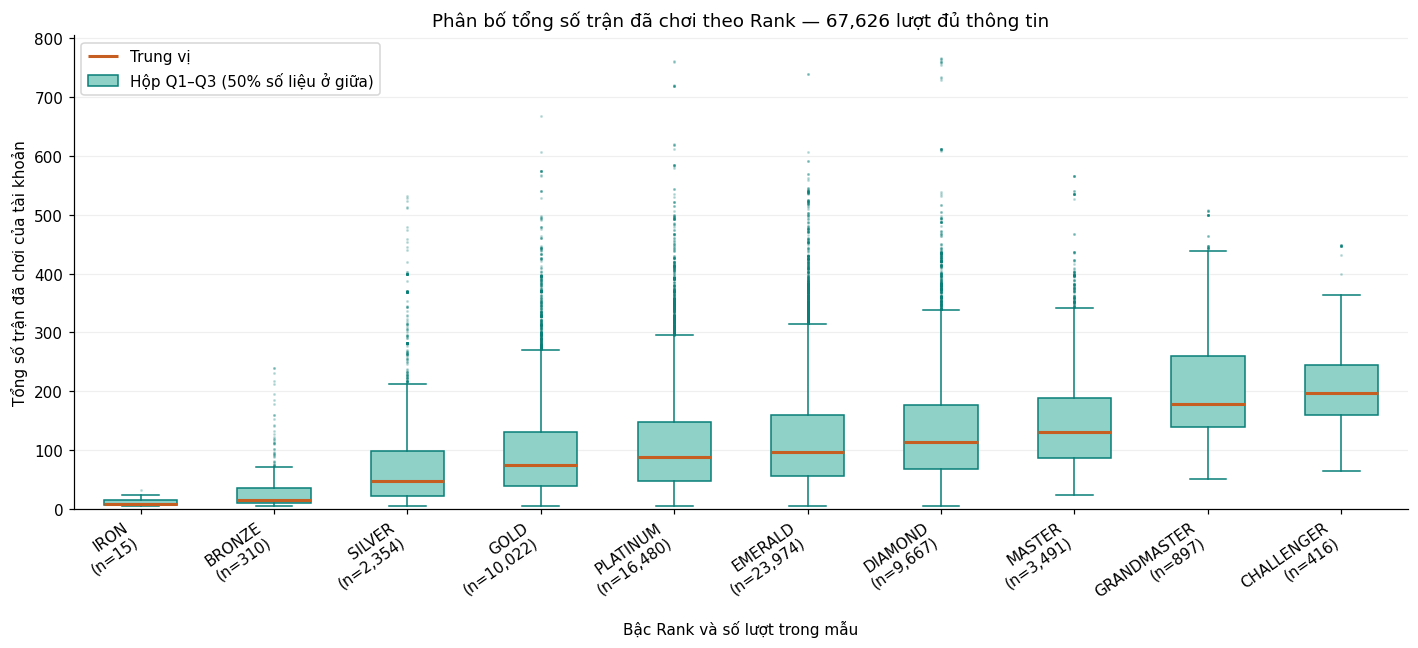


**Cách đọc:** mỗi hộp là một phân bố. Vạch cam trong hộp là trung vị;
chiều cao hộp là khoảng Q1–Q3. Râu và các chấm cho thấy phần số liệu bên ngoài hộp.
Ví dụ Gold có trung vị 75 trận,
với hộp từ 38 đến
131 trận.

**Nhận xét:** trên **67,626 lượt đủ Rank**, trung vị số trận tài khoản
được ghi nhận là **75** ở Gold,
**113** ở Diamond và
**130** ở Master.
Trong mẫu này, các bậc cao hơn đi kèm trung vị tổng số trận tài khoản lớn hơn;
khoảng Q1–Q3 giữa nhiều bậc vẫn chồng lấn.

**Giới hạn:** Iron chỉ có 15 lượt.
Tài khoản có thể xuất hiện nhiều lần nên đây là mô tả theo lượt, chưa phải thống kê
trên người chơi duy nhất. Không thể kết luận chơi nhiều gây tăng Rank hoặc cần
chơi đúng một số trận nhất định để đạt một bậc. Đây cũng không phải số trận
của bộ CSV; bộ CSV có 6,830 trận riêng biệt.


In [9]:
# Tổng thắng + thua là thống kê tài khoản được ghi nhận trên từng lượt.
rank_valid['solo_total_games'] = rank_valid['solo_wins'] + rank_valid['solo_losses']
rank_activity_summary = rank_valid.groupby('solo_tier')['solo_total_games'].agg(
    so_luot='size', trung_binh='mean', trung_vi='median', nho_nhat='min', lon_nhat='max'
).reindex(tier_order_all)
rank_activity_summary['q25'] = rank_valid.groupby('solo_tier')['solo_total_games'].quantile(0.25)
rank_activity_summary['q75'] = rank_valid.groupby('solo_tier')['solo_total_games'].quantile(0.75)
display(bang_tieng_viet(rank_activity_summary.round(2)))

# Mỗi hộp dùng toàn bộ giá trị số trận của bậc đó; chỉ bỏ bậc không có quan sát.
plot_data = rank_activity_summary.dropna(subset=['trung_vi']).copy()
games_by_tier = [
    rank_valid.loc[rank_valid['solo_tier'].eq(tier), 'solo_total_games']
    for tier in plot_data.index
]
fig, ax = plt.subplots(figsize=(13, 6))
boxes = ax.boxplot(
    games_by_tier, patch_artist=True, widths=0.55, whis=1.5,
    boxprops={'facecolor': TEAL_LIGHT, 'edgecolor': TEAL},
    medianprops={'color': '#C65D21', 'linewidth': 2},
    whiskerprops={'color': TEAL}, capprops={'color': TEAL},
    flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2,
                'markerfacecolor': TEAL, 'markeredgecolor': TEAL}
)
ax.set_xticks(range(1, len(plot_data) + 1), [
    f'{tier}\n(n={int(row["so_luot"]):,})' for tier, row in plot_data.iterrows()
], rotation=35, ha='right')
ax.set(
    title=f'Phân bố tổng số trận đã chơi theo Rank — {len(rank_valid):,} lượt đủ thông tin',
    xlabel='Bậc Rank và số lượt trong mẫu',
    ylabel='Tổng số trận đã chơi của tài khoản'
)
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.2)
ax.legend([boxes['medians'][0], boxes['boxes'][0]],
          ['Trung vị', 'Hộp Q1–Q3 (50% số liệu ở giữa)'], loc='upper left')
plt.tight_layout()
plt.show()

display(Markdown(f"""
**Cách đọc:** mỗi hộp là một phân bố. Vạch cam trong hộp là trung vị;
chiều cao hộp là khoảng Q1–Q3. Râu và các chấm cho thấy phần số liệu bên ngoài hộp.
Ví dụ Gold có trung vị {rank_activity_summary.loc['GOLD', 'trung_vi']:.0f} trận,
với hộp từ {rank_activity_summary.loc['GOLD', 'q25']:.0f} đến
{rank_activity_summary.loc['GOLD', 'q75']:.0f} trận.

**Nhận xét:** trên **{len(rank_valid):,} lượt đủ Rank**, trung vị số trận tài khoản
được ghi nhận là **{rank_activity_summary.loc['GOLD', 'trung_vi']:.0f}** ở Gold,
**{rank_activity_summary.loc['DIAMOND', 'trung_vi']:.0f}** ở Diamond và
**{rank_activity_summary.loc['MASTER', 'trung_vi']:.0f}** ở Master.
Trong mẫu này, các bậc cao hơn đi kèm trung vị tổng số trận tài khoản lớn hơn;
khoảng Q1–Q3 giữa nhiều bậc vẫn chồng lấn.

**Giới hạn:** Iron chỉ có {int(rank_activity_summary.loc['IRON', 'so_luot'])} lượt.
Tài khoản có thể xuất hiện nhiều lần nên đây là mô tả theo lượt, chưa phải thống kê
trên người chơi duy nhất. Không thể kết luận chơi nhiều gây tăng Rank hoặc cần
chơi đúng một số trận nhất định để đạt một bậc. Đây cũng không phải số trận
của bộ CSV; bộ CSV có {n_games:,} trận riêng biệt.
"""))


### 2.4. Tổng số trận đã chơi và tỷ lệ thắng của tài khoản

`solo_wins`/`solo_losses` là thống kê tài khoản được ghi nhận trên từng lượt,
khác `win` của trận trong CSV. Không cộng các cột này để đếm trận của bộ dữ liệu.
Tổng và tỷ lệ dưới đây vẫn được mô tả ở **cấp lượt**, không phải tài khoản duy nhất.
Mẫu số 0 được đổi thành thiếu bằng `where()`.


,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),P95 (95%),P99 (99%),Lớn nhất
Số trận thắng Solo/Duo,"67,626.00",59.88,44.42,0.00,27.00,50.00,82.00,147.00,199.00,373.00
Số trận thua Solo/Duo,"67,626.00",55.91,42.43,0.00,25.00,46.00,76.00,139.00,194.00,396.00
Tổng số trận đã chơi,"67,626.00",115.79,86.23,5.00,52.00,95.00,158.00,286.00,393.00,767.00
Tỷ lệ thắng tài khoản (%),"67,626.00",51.78,7.34,0.00,48.44,51.61,55.11,63.16,73.68,100.00


,Số lượt,Trung vị tổng số trận đã chơi,Trung vị tỷ lệ thắng (%)
Bậc Rank Solo/Duo,,,
IRON,15,9.00,50.00
BRONZE,310,15.00,50.00
SILVER,2354,48.00,50.00
GOLD,10022,75.00,50.28
PLATINUM,16480,88.00,50.78
EMERALD,23974,97.00,51.77
DIAMOND,9667,113.00,52.55
MASTER,3491,130.00,53.64
GRANDMASTER,897,179.00,54.68


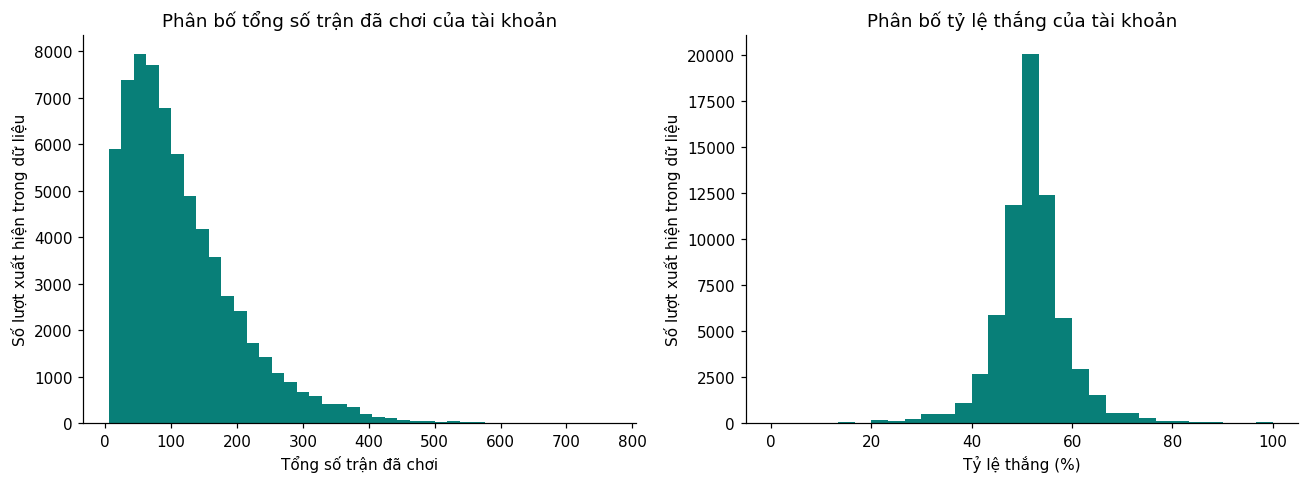


**Nhận xét:** trên 67,626 lượt đủ rank, trung vị số trận tài khoản được
ghi nhận là **95**, trung vị tỷ lệ thắng là
**51.61%**.
Có 0 lượt có mẫu số 0 trong mẫu này.
Không suy ra số tài khoản hoặc kinh nghiệm duy nhất vì tài khoản có thể lặp lại;
thời điểm ghi nhận thống kê tài khoản so với trận chưa được xác minh.


In [10]:
# solo_total_games đã được tạo ở mục 2.3.
rank_valid['account_win_rate_pct'] = (
    rank_valid['solo_wins'] / rank_valid['solo_total_games'].where(rank_valid['solo_total_games'].gt(0)) * 100
)
account_cols = ['solo_wins', 'solo_losses', 'solo_total_games', 'account_win_rate_pct']
display(bang_tieng_viet(rank_valid[account_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T))
account_by_tier = rank_valid.groupby('solo_tier').agg(
    so_luot=('solo_lp', 'size'), trung_vi_tong_tran=('solo_total_games', 'median'),
    trung_vi_ty_le_thang_pct=('account_win_rate_pct', 'median')
).reindex(tier_order_all)
display(bang_tieng_viet(account_by_tier.round(2)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(rank_valid['solo_total_games'], bins=40, color=TEAL)
axes[0].set(title='Phân bố tổng số trận đã chơi của tài khoản',
            xlabel='Tổng số trận đã chơi', ylabel='Số lượt xuất hiện trong dữ liệu')
axes[1].hist(rank_valid['account_win_rate_pct'].dropna(), bins=30, color=TEAL)
axes[1].set(title='Phân bố tỷ lệ thắng của tài khoản',
            xlabel='Tỷ lệ thắng (%)', ylabel='Số lượt xuất hiện trong dữ liệu')
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** trên {len(rank_valid):,} lượt đủ rank, trung vị số trận tài khoản được
ghi nhận là **{rank_valid['solo_total_games'].median():.0f}**, trung vị tỷ lệ thắng là
**{rank_valid['account_win_rate_pct'].median():.2f}%**.
Có {rank_valid['solo_total_games'].eq(0).sum():,} lượt có mẫu số 0 trong mẫu này.
Không suy ra số tài khoản hoặc kinh nghiệm duy nhất vì tài khoản có thể lặp lại;
thời điểm ghi nhận thống kê tài khoản so với trận chưa được xác minh.
"""))


## 3. Khám phá Thông thạo (Mastery)

### 3.1. Chất lượng và thời điểm ghi nhận

Kiểm tra đủ 6 trường: thiếu, 0, âm và phân vị. Giá trị 0 không được tự đồng nhất
với thiếu. `mastery_lastPlayTime` có dạng epoch mili giây; chỉ chuyển những giá trị
dương thành UTC để kiểm tra độ hợp lý, giữ 0 trong bảng gốc và không gọi đó là năm 1970.
Chưa có tài liệu nguồn để xác nhận ý nghĩa các nhóm 0 hoặc quy tắc lên cấp theo mùa.


In [11]:
mastery_df = eda_df[mastery_cols].copy()
mastery_quality = pd.DataFrame({
    'so_o_thieu': mastery_df.isna().sum(),
    'so_gia_tri_0': mastery_df.eq(0).sum(),
    'ty_le_0_pct': mastery_df.eq(0).mean() * 100,
    'so_gia_tri_am': mastery_df.lt(0).sum(),
    'nho_nhat': mastery_df.min(), 'lon_nhat': mastery_df.max()
})
display(bang_tieng_viet(mastery_quality))
mastery_zero_mask = eda_df['mastery_points'].eq(0)
mastery_all_zero_mask = mastery_df.eq(0).all(axis=1)
mastery_time = pd.to_datetime(
    eda_df['mastery_lastPlayTime'].where(eda_df['mastery_lastPlayTime'].gt(0)),
    unit='ms', utc=True, errors='coerce'
)
match_end = eda_df['start_datetime'] + pd.to_timedelta(eda_df['duration'], unit='s')
time_valid = mastery_time.notna()
mastery_after_match_pct = mastery_time[time_valid].gt(match_end[time_valid]).mean() * 100
display(Markdown(f"""
**Nhận xét:** {mastery_zero_mask.sum():,} lượt có điểm Mastery 0
(**{mastery_zero_mask.mean() * 100:.2f}%** trên {n_rows:,} lượt);
{mastery_all_zero_mask.sum():,} lượt có cả 6 trường bằng 0.
Giữ nguyên nhóm này và công bố thống kê riêng, chưa kết luận là chưa chơi tướng
hay lỗi thu thập. Khi đọc timestamp dương như epoch ms, có
**{mastery_after_match_pct:.2f}%** trong {time_valid.sum():,} lượt có thời điểm Mastery
sau lúc kết thúc trận tính từ `start_utc + duration`.
Điều này cho thấy không thể mặc định Mastery là đặc trưng có sẵn trước trận.
"""))


,Số ô thiếu,Số giá trị bằng 0,Tỷ lệ bằng 0 (%),Số giá trị âm,Nhỏ nhất,Lớn nhất
Cấp thông thạo,0,771,1.13,0,0,835
Điểm thông thạo,0,771,1.13,0,0,10024014
Thời điểm chơi gần nhất (ms),0,771,1.13,0,0,1740074969000
Điểm từ cấp gần nhất,0,1046,1.53,0,0,1587297
Điểm tới cấp kế tiếp,0,23707,34.71,0,0,23693
Số token thông thạo,0,18205,26.65,0,0,38



**Nhận xét:** 771 lượt có điểm Mastery 0
(**1.13%** trên 68,300 lượt);
771 lượt có cả 6 trường bằng 0.
Giữ nguyên nhóm này và công bố thống kê riêng, chưa kết luận là chưa chơi tướng
hay lỗi thu thập. Khi đọc timestamp dương như epoch ms, có
**99.19%** trong 67,529 lượt có thời điểm Mastery
sau lúc kết thúc trận tính từ `start_utc + duration`.
Điều này cho thấy không thể mặc định Mastery là đặc trưng có sẵn trước trận.


### 3.2. Phân bố level và points

Histogram đếm lượt trong từng khoảng giá trị. Dùng `log10(1 + x)` để nén đuôi dài;
giá trị 0 chuyển thành 0 và vẫn được giữ. Nhãn trục được đổi về số điểm/cấp gốc.


,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),P90 (90%),P95 (95%),P99 (99%),Lớn nhất
Cấp thông thạo,"68,300.00",22.28,38.42,0.00,5.00,9.00,22.00,55.00,88.00,188.00,835.00
Điểm thông thạo,"68,300.00","240,147.75","464,242.65",0.00,"25,956.50","77,603.00","241,018.50","643,486.90","1,029,217.50","2,247,914.00","10,024,014.00"


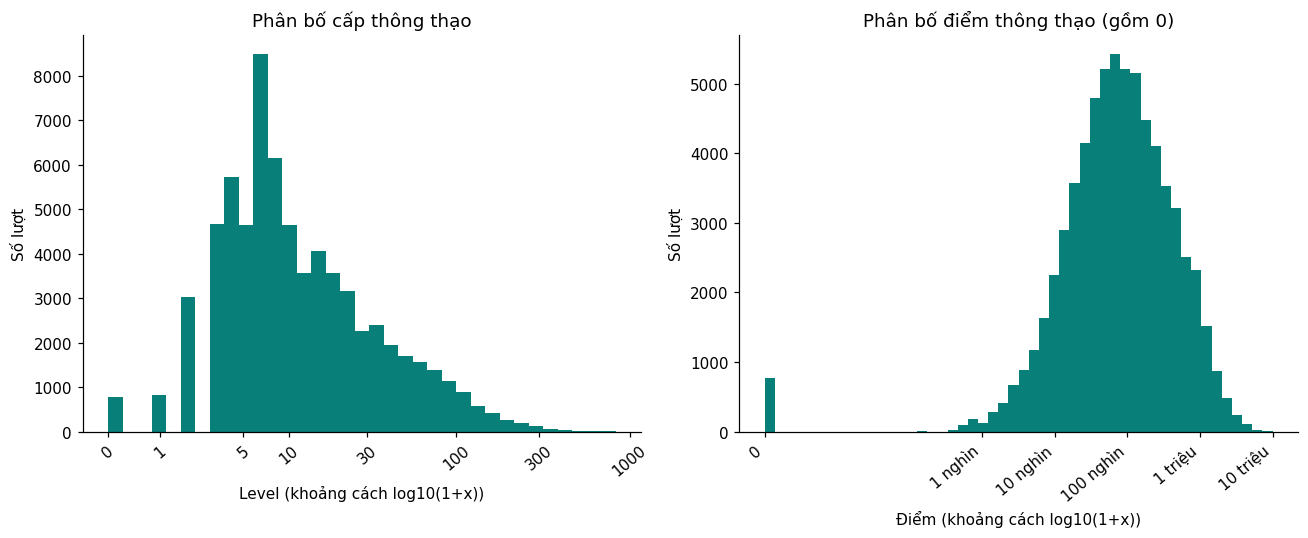


**Nhận xét:** điểm Mastery có trung bình **240,148**, trung vị
**77,603**, Q1 **25,956.5**, Q3 **241,018.5**;
P95 **1,029,217.5**, P99 **2,247,914**,
lớn nhất **10,024,014**. Trung bình lớn hơn trung vị
3.09 lần, phù hợp phân bố lệch phải.
Ngưỡng tham khảo Q3 + 1,5×IQR là 563,611.5;
7,925 lượt (11.60%) vượt ngưỡng.
Đây là cờ thống kê, không phải căn cứ xóa dữ liệu.
Nếu chỉ xem 67,529 lượt có điểm dương, trung vị là
79,558; thống kê chính vẫn giữ nhóm 0.


In [12]:
mastery_summary = mastery_df[['mastery_level', 'mastery_points']].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).T
display(bang_tieng_viet(mastery_summary))
points = eda_df['mastery_points']
points_positive = points[points.gt(0)]
q1, q3 = points.quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
iqr_outlier_count = int(points.gt(iqr_upper).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(np.log10(1 + eda_df['mastery_level']), bins=35, color=TEAL)
level_ticks = np.array([0, 1, 5, 10, 30, 100, 300, 1000])
axes[0].set_xticks(np.log10(1 + level_ticks), level_ticks, rotation=40)
axes[0].set(title='Phân bố cấp thông thạo', xlabel='Level (khoảng cách log10(1+x))', ylabel='Số lượt')
axes[1].hist(np.log10(1 + points), bins=50, color=TEAL)
point_ticks = np.array([0, 1000, 10000, 100000, 1000000, 10000000])
axes[1].set_xticks(np.log10(1 + point_ticks), ['0', '1 nghìn', '10 nghìn', '100 nghìn', '1 triệu', '10 triệu'], rotation=40, ha='right')
axes[1].set(title='Phân bố điểm thông thạo (gồm 0)', xlabel='Điểm (khoảng cách log10(1+x))', ylabel='Số lượt')
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** điểm Mastery có trung bình **{points.mean():,.0f}**, trung vị
**{points.median():,.0f}**, Q1 **{q1:,.1f}**, Q3 **{q3:,.1f}**;
P95 **{points.quantile(0.95):,.1f}**, P99 **{points.quantile(0.99):,.0f}**,
lớn nhất **{points.max():,}**. Trung bình lớn hơn trung vị
{points.mean() / points.median():.2f} lần, phù hợp phân bố lệch phải.
Ngưỡng tham khảo Q3 + 1,5×IQR là {iqr_upper:,.1f};
{iqr_outlier_count:,} lượt ({iqr_outlier_count / n_rows * 100:.2f}%) vượt ngưỡng.
Đây là cờ thống kê, không phải căn cứ xóa dữ liệu.
Nếu chỉ xem {len(points_positive):,} lượt có điểm dương, trung vị là
{points_positive.median():,.0f}; thống kê chính vẫn giữ nhóm 0.
"""))


### 3.3. Các trường tiến độ và token

Mô tả phân bố các trường phụ thay vì suy đoán cơ chế lên cấp.
Số điểm còn thiếu bằng 0 không tự chứng minh đã sẵn sàng lên cấp;
thời điểm và quy tắc của phiên bản dữ liệu chưa được xác nhận.


,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),P95 (95%),P99 (99%),Lớn nhất
Điểm từ cấp gần nhất,"68,300.00","27,315.03","64,215.43",0.00,"3,066.00","7,119.00","27,380.00","113,761.70","309,441.63","1,587,297.00"
Điểm tới cấp kế tiếp,"68,300.00","3,192.22","3,440.05",0.00,0.00,"2,078.00","5,843.00","9,733.00","10,829.00","23,693.00"
Số token thông thạo,"68,300.00",2.83,3.46,0.00,0.00,1.00,5.00,9.00,15.00,38.00


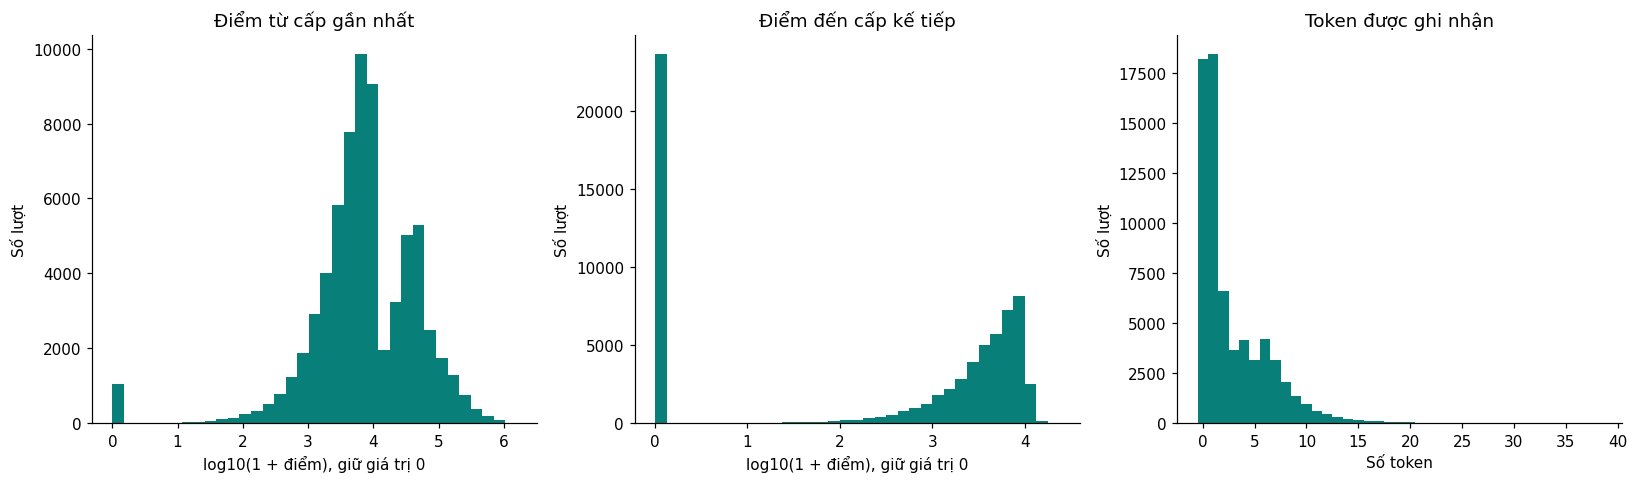


**Nhận xét:** `mastery_pointsUntilNextLevel` bằng 0 ở
23,707 lượt
(34.71%).
Token có trung vị 1,
lớn nhất 38.
Các số này mô tả dữ liệu ghi nhận, chưa đủ để giải thích điều kiện lên cấp.


In [13]:
progress_cols = ['mastery_pointsSinceLastLevel', 'mastery_pointsUntilNextLevel', 'mastery_tokens']
display(bang_tieng_viet(mastery_df[progress_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title in zip(axes[:2], progress_cols[:2], ['Điểm từ cấp gần nhất', 'Điểm đến cấp kế tiếp']):
    ax.hist(np.log10(1 + mastery_df[col]), bins=35, color=TEAL)
    ax.set(title=title, xlabel='log10(1 + điểm), giữ giá trị 0', ylabel='Số lượt')
axes[2].hist(mastery_df['mastery_tokens'], bins=np.arange(0, mastery_df['mastery_tokens'].max() + 2) - 0.5, color=TEAL)
axes[2].set(title='Token được ghi nhận', xlabel='Số token', ylabel='Số lượt')
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** `mastery_pointsUntilNextLevel` bằng 0 ở
{mastery_df['mastery_pointsUntilNextLevel'].eq(0).sum():,} lượt
({mastery_df['mastery_pointsUntilNextLevel'].eq(0).mean() * 100:.2f}%).
Token có trung vị {mastery_df['mastery_tokens'].median():.0f},
lớn nhất {mastery_df['mastery_tokens'].max():.0f}.
Các số này mô tả dữ liệu ghi nhận, chưa đủ để giải thích điều kiện lên cấp.
"""))


## 4. Khám phá Vị trí

Ba nhãn `Invalid` trong dữ liệu gốc đã được sửa theo yêu cầu: Yuumi và Lulu
thành `SUPPORT`; Volibear thành `TOP` vì đồng đội Master Yi đã ở `JUNGLE`,
còn các vị trí MIDDLE, BOTTOM và SUPPORT đều đã có người.

Các thay đổi được áp dụng theo khóa `game_id` + `participant_id` trên bảng
phân tích. CSV gốc được giữ nguyên.
Các phép thống kê theo vị trí dùng nhãn đã sửa. Tiếp tục kiểm tra cơ cấu
vị trí ở cấp đội, vì đủ 5 người không đồng nghĩa mỗi vị trí đúng 1 người.


,Số lượt,Tỷ trọng trên toàn bộ dữ liệu (%)
Vị trí,,
TOP,13661,20.00
JUNGLE,13743,20.12
MIDDLE,13654,19.99
BOTTOM,13666,20.01
SUPPORT,13576,19.88


,Loại đội,Số đội–trận
0,Mỗi vị trí hợp lệ đúng 1 lượt,13534
1,Cơ cấu vị trí khác,126


,Vị trí,TOP,JUNGLE,MIDDLE,BOTTOM,SUPPORT
Mã trận,Nhóm đội,,,,,
3736516173,Thắng,1,2,1,1,0
3737018402,Thắng,1,2,1,1,0
3737161849,Thua,1,2,1,1,0
3737696082,Thua,1,2,1,1,0
3737780107,Thua,1,1,1,2,0
3739184252,Thắng,1,2,1,1,0
3739363436,Thắng,1,1,1,2,0
3739601460,Thắng,1,1,1,2,0
3740326911,Thua,1,2,1,1,0


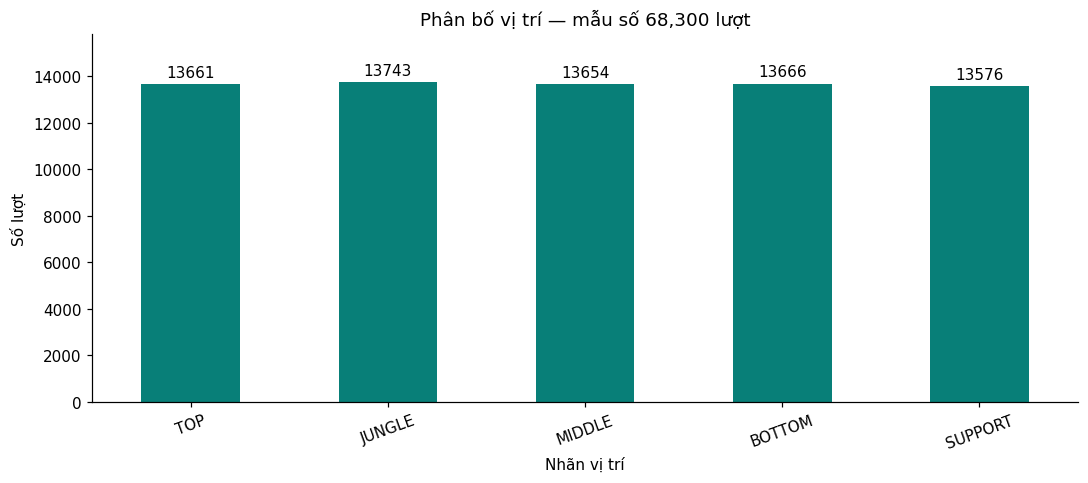


**Nhận xét:** giữ **68,300/68,300 lượt**
(100.0000%) trong phân tích theo vị trí hợp lệ;
Dữ liệu gốc có 3 lượt mang nhãn Invalid;
đã sửa 3 lượt theo chỉ định và đối chiếu đội hình.
Sau sửa còn 0 lượt không có vị trí hợp lệ.
Số lượt giữa 5 vị trí khá gần nhau, từ
13,576 đến 13,743.
Tuy vậy, **126/13,660 đội–trận** không có đúng 1 lượt
ở mỗi vị trí hợp lệ. Chưa biết đây là lỗi suy luận vị trí hay đội hình thực tế;
các bảng tiếp theo phản ánh **nhãn được ghi nhận**, không khẳng định đội hình chuẩn.


In [14]:
position_labels = eda_df['position'].fillna('MISSING')
position_counts = position_labels.value_counts()
position_counts = position_counts.reindex(position_order + [x for x in position_counts.index if x not in position_order])
position_summary = pd.DataFrame({
    'so_luot': position_counts, 'ty_trong_tren_toan_bo_pct': position_counts / n_rows * 100
})
display(bang_tieng_viet(position_summary))
position_valid_mask = eda_df['position'].isin(position_order)
position_valid_df = eda_df.loc[position_valid_mask].copy()
invalid_rows = eda_df.loc[~position_valid_mask, [
    'game_id', 'participant_id', 'champion_name', 'position', 'win', 'duration_min'
]]
if not invalid_rows.empty:
    display(bang_tieng_viet(invalid_rows))

team_role_counts = pd.crosstab(
    [eda_df['game_id'], eda_df['win']], eda_df['position']
).reindex(columns=position_order, fill_value=0)
team_role_ok = team_role_counts.eq(1).all(axis=1)
display(bang_tieng_viet(pd.DataFrame({
    'loai_doi': ['Mỗi vị trí hợp lệ đúng 1 lượt', 'Cơ cấu vị trí khác'],
    'so_doi_tran': [team_role_ok.sum(), (~team_role_ok).sum()]
})))
display(bang_tieng_viet(team_role_counts.loc[~team_role_ok].head(10)))
ax = position_counts.plot(kind='bar', color=TEAL, figsize=(10, 4.5))
ax.bar_label(ax.containers[0], padding=3)
ax.set(title=f'Phân bố vị trí — mẫu số {n_rows:,} lượt', xlabel='Nhãn vị trí', ylabel='Số lượt')
ax.set_ylim(0, position_counts.max() * 1.15)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** giữ **{len(position_valid_df):,}/{n_rows:,} lượt**
({position_valid_mask.mean() * 100:.4f}%) trong phân tích theo vị trí hợp lệ;
Dữ liệu gốc có {raw_invalid_position_count} lượt mang nhãn Invalid;
đã sửa {len(position_corrections)} lượt theo chỉ định và đối chiếu đội hình.
Sau sửa còn {len(invalid_rows)} lượt không có vị trí hợp lệ.
Số lượt giữa 5 vị trí khá gần nhau, từ
{position_counts.reindex(position_order).min():,} đến {position_counts.reindex(position_order).max():,}.
Tuy vậy, **{(~team_role_ok).sum():,}/{len(team_role_ok):,} đội–trận** không có đúng 1 lượt
ở mỗi vị trí hợp lệ. Chưa biết đây là lỗi suy luận vị trí hay đội hình thực tế;
các bảng tiếp theo phản ánh **nhãn được ghi nhận**, không khẳng định đội hình chuẩn.
"""))


## 5. Khám phá Tướng

### 5.1. Ánh xạ mã–tên và mức phổ biến

`champion_id` là mã phân loại, không tính trung bình mã tướng.
Đếm lượt của từng tướng và tỷ trọng trên toàn bộ lượt. Bổ sung tỷ lệ trận có tướng:
đếm số `game_id` khác nhau có tướng chia tổng số trận; khác tỷ trọng lượt chọn.
Chọn top 15 chỉ để biểu đồ dễ đọc, bảng đầy đủ vẫn được lưu.


,Mã tướng,Số lượt,Số trận có tướng,Tỷ trọng lượt xuất hiện (%),Tỷ lệ trận có tướng (%)
Tên tướng,,,,,
Jinx,222,1624,1624,2.38,23.78
Caitlyn,51,1271,1271,1.86,18.61
Lulu,117,1237,1237,1.81,18.11
Mel,800,1204,1204,1.76,17.63
Ezreal,81,1168,1168,1.71,17.10
Diana,131,1134,1134,1.66,16.60
Nami,267,1032,1032,1.51,15.11
Jhin,202,1005,1005,1.47,14.71
Lux,99,968,968,1.42,14.17


,Giá trị
Thống kê lượt xuất hiện của tướng,
Số tướng trong dữ liệu,170.00
Số lượt xuất hiện trung bình mỗi tướng,401.76
Độ lệch chuẩn số lượt giữa các tướng,269.39
Số lượt của tướng xuất hiện ít nhất,72.00
Q1 — phân vị 25% số lượt xuất hiện,208.00
Trung vị số lượt xuất hiện mỗi tướng,332.50
Q3 — phân vị 75% số lượt xuất hiện,502.00
Số lượt của tướng xuất hiện nhiều nhất,"1,624.00"


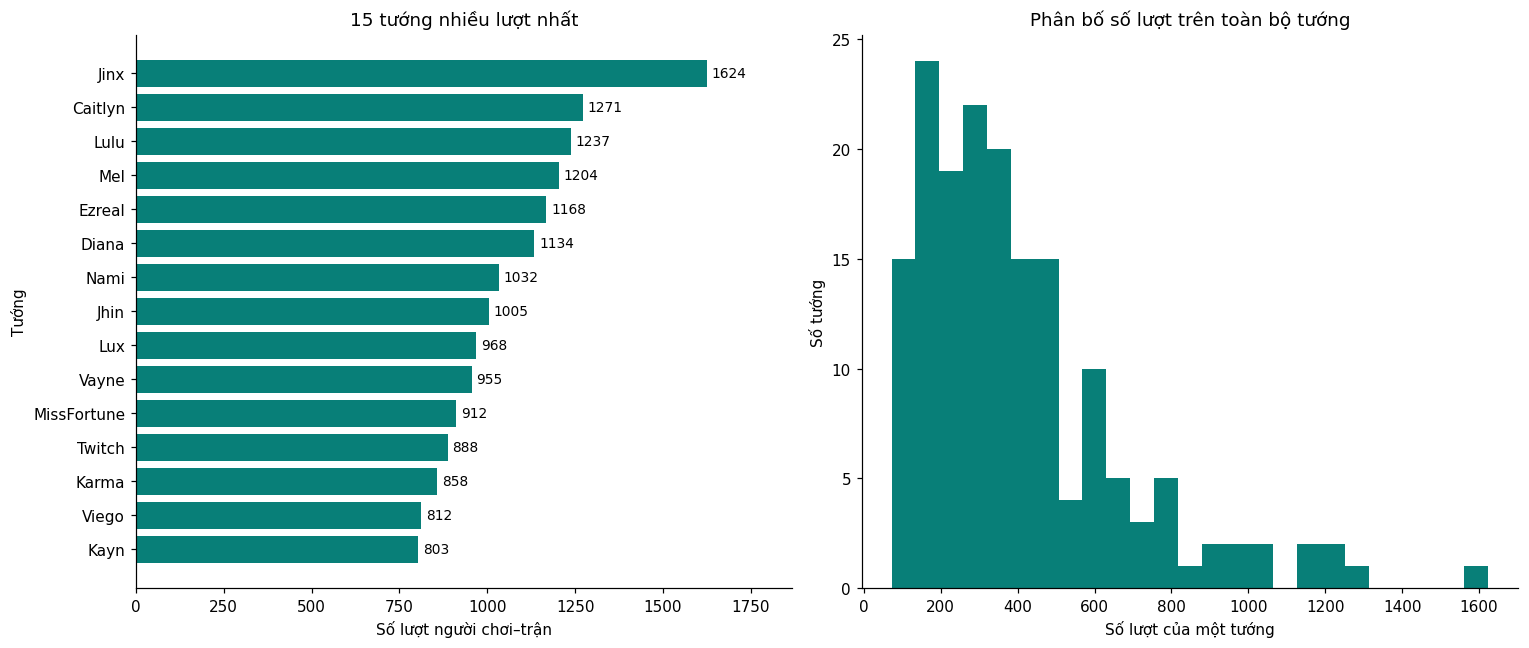


**Nhận xét:** 170 mã và 170 tên có ánh xạ một-một.
**Jinx** có nhiều lượt nhất: 1,624
lượt, chiếm 2.38% toàn bộ lượt và xuất hiện
trong 23.78% số trận.
Số lượt mỗi tướng từ 72 đến
1,624; top 15 chiếm
23.24% số lượt.
Độ phổ biến trong mẫu không phản ánh lượt cấm hoặc sức mạnh của tướng.


In [15]:
champion_missing = eda_df[['champion_id', 'champion_name']].isna().sum()
id_to_name = eda_df.groupby('champion_id')['champion_name'].nunique(dropna=False)
name_to_id = eda_df.groupby('champion_name')['champion_id'].nunique(dropna=False)
assert champion_missing.eq(0).all(), 'Có mã/tên tướng bị thiếu.'
assert id_to_name.eq(1).all() and name_to_id.eq(1).all(), 'Ánh xạ mã–tên không một-một.'
champion_summary = eda_df.groupby('champion_name').agg(
    champion_id=('champion_id', 'first'), so_luot=('participant_id', 'size'),
    so_tran_co_tuong=('game_id', 'nunique')
).sort_values('so_luot', ascending=False)
champion_summary['ty_trong_luot_pct'] = champion_summary['so_luot'] / n_rows * 100
champion_summary['ty_le_tran_co_tuong_pct'] = champion_summary['so_tran_co_tuong'] / n_games * 100
display(bang_tieng_viet(champion_summary.head(15)))
# Hàng đầu đếm số tướng; các hàng còn lại mô tả số lượt xuất hiện mỗi tướng.
champion_frequency_stats = (
    champion_summary['so_luot'].describe()
    .rename(index={
        'count': 'Số tướng trong dữ liệu',
        'mean': 'Số lượt xuất hiện trung bình mỗi tướng',
        'std': 'Độ lệch chuẩn số lượt giữa các tướng',
        'min': 'Số lượt của tướng xuất hiện ít nhất',
        '25%': 'Q1 — phân vị 25% số lượt xuất hiện',
        '50%': 'Trung vị số lượt xuất hiện mỗi tướng',
        '75%': 'Q3 — phân vị 75% số lượt xuất hiện',
        'max': 'Số lượt của tướng xuất hiện nhiều nhất'
    })
    .rename_axis('Thống kê lượt xuất hiện của tướng')
    .to_frame(name='Giá trị')
)
display(bang_tieng_viet(champion_frequency_stats))
top_champions = champion_summary.head(15).index.tolist()
top15 = champion_summary.loc[top_champions].iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top15.index, top15['so_luot'], color=TEAL)
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
axes[0].set(title='15 tướng nhiều lượt nhất', xlabel='Số lượt người chơi–trận', ylabel='Tướng')
axes[0].set_xlim(0, top15['so_luot'].max() * 1.15)
axes[1].hist(champion_summary['so_luot'], bins=25, color=TEAL)
axes[1].set(title='Phân bố số lượt trên toàn bộ tướng', xlabel='Số lượt của một tướng', ylabel='Số tướng')
plt.tight_layout()
plt.show()
top_champion_name = champion_summary.index[0]
display(Markdown(f"""
**Nhận xét:** {len(id_to_name):,} mã và {len(name_to_id):,} tên có ánh xạ một-một.
**{top_champion_name}** có nhiều lượt nhất: {champion_summary.iloc[0]['so_luot']:,.0f}
lượt, chiếm {champion_summary.iloc[0]['ty_trong_luot_pct']:.2f}% toàn bộ lượt và xuất hiện
trong {champion_summary.iloc[0]['ty_le_tran_co_tuong_pct']:.2f}% số trận.
Số lượt mỗi tướng từ {champion_summary['so_luot'].min():,} đến
{champion_summary['so_luot'].max():,}; top 15 chiếm
{champion_summary.head(15)['ty_trong_luot_pct'].sum():.2f}% số lượt.
Độ phổ biến trong mẫu không phản ánh lượt cấm hoặc sức mạnh của tướng.
"""))


### 5.2. Quan hệ tướng–vị trí

Chỉ dùng các nhãn vị trí hợp lệ. Heatmap hiển thị top 15 theo số lượt trong toàn mẫu;
mỗi hàng là tỷ lệ vị trí **trong các lượt hợp lệ của chính tướng đó**, cộng thành 100%.
`n` ở nhãn hàng là mẫu số sau lọc, không phải tổng lượt của cả 15 tướng.


Vị trí,TOP,JUNGLE,MIDDLE,BOTTOM,SUPPORT,Tổng số lượt hợp lệ
Tên tướng,,,,,,
Jinx,2,2,1,1618,1,1624
Caitlyn,8,0,16,1243,4,1271
Lulu,3,1,6,0,1227,1237
Mel,37,1,858,131,177,1204
Ezreal,7,0,28,1131,2,1168
Diana,5,986,140,3,0,1134
Nami,0,1,1,2,1028,1032
Jhin,7,0,12,986,0,1005
Lux,4,1,415,47,501,968


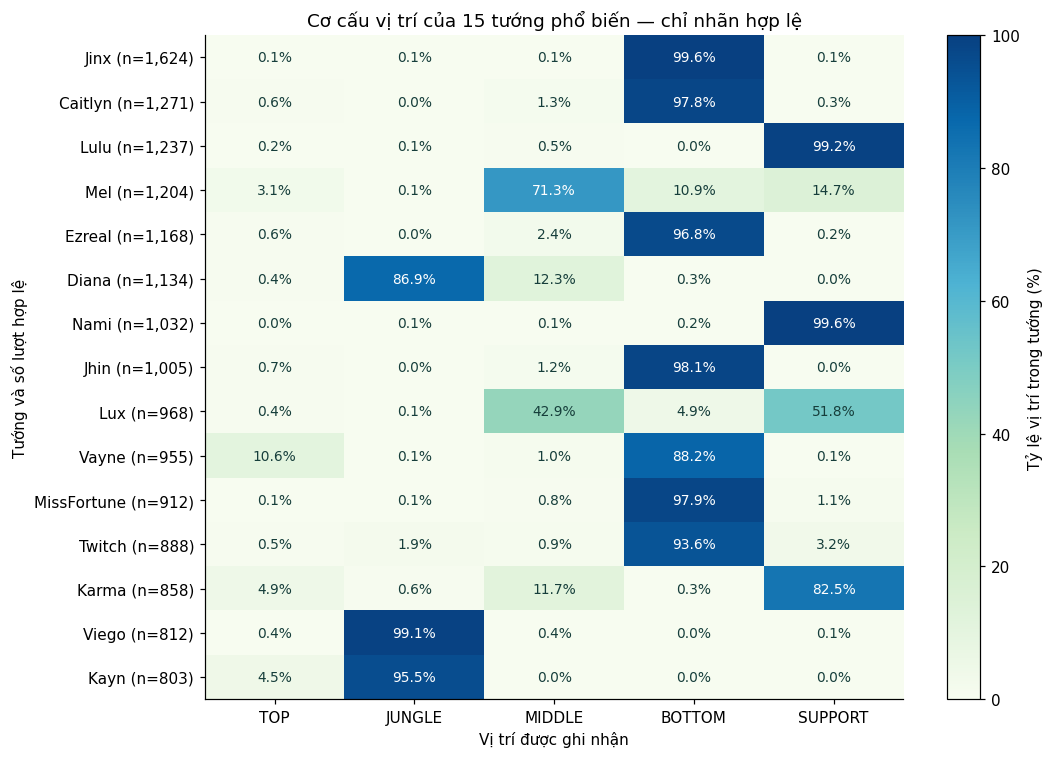


**Nhận xét:** trên 68,300 lượt hợp lệ,
86/170 tướng có ít nhất
90% số lượt ở cùng một vị trí được ghi nhận. Đây là mức tập trung theo nhãn trong mẫu;
không kết luận các vị trí khác là sai hoặc không thể chơi.
Các dòng Invalid không được dùng để chuẩn hóa tỷ lệ trên heatmap.


In [16]:
champion_position_counts = pd.crosstab(
    position_valid_df['champion_name'], position_valid_df['position']
).reindex(columns=position_order, fill_value=0)
champion_position_pct = champion_position_counts.div(champion_position_counts.sum(axis=1), axis=0) * 100
top_champion_position_pct = champion_position_pct.reindex(top_champions)
display(bang_tieng_viet(champion_position_counts.reindex(top_champions).assign(
    tong_luot_hop_le=champion_position_counts.reindex(top_champions).sum(axis=1)
)))
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(top_champion_position_pct, cmap='GnBu', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(position_order)), position_order)
ax.set_yticks(range(len(top_champions)), [
    f'{name} (n={champion_position_counts.loc[name].sum():,})' for name in top_champions
])
for i in range(len(top_champions)):
    for j in range(len(position_order)):
        value = top_champion_position_pct.iloc[i, j]
        ax.text(j, i, f'{value:.1f}%', ha='center', va='center', color='white' if value > 55 else '#163E3B', fontsize=9)
fig.colorbar(im, ax=ax, label='Tỷ lệ vị trí trong tướng (%)')
ax.set(title='Cơ cấu vị trí của 15 tướng phổ biến — chỉ nhãn hợp lệ', xlabel='Vị trí được ghi nhận', ylabel='Tướng và số lượt hợp lệ')
plt.tight_layout()
plt.show()
dominant_position_share = champion_position_pct.max(axis=1)
display(Markdown(f"""
**Nhận xét:** trên {len(position_valid_df):,} lượt hợp lệ,
{dominant_position_share.ge(90).sum():,}/{len(dominant_position_share):,} tướng có ít nhất
90% số lượt ở cùng một vị trí được ghi nhận. Đây là mức tập trung theo nhãn trong mẫu;
không kết luận các vị trí khác là sai hoặc không thể chơi.
Các dòng Invalid không được dùng để chuẩn hóa tỷ lệ trên heatmap.
"""))


## 6. Mục tiêu lớn và công trình

### 6.1. Tạo bảng một dòng cho mỗi đội–trận

Trước khi lấy dòng đại diện, kiểm tra mọi chỉ số mục tiêu và thời lượng đều
giống nhau trên 5 dòng của đội. Dùng khóa **`game_id` + `win`** sau khi đã xác nhận
mỗi trận có đúng hai nhóm 5 người. Khóa này phù hợp **mô tả hồi cứu**; chứa kết quả
nên không dùng để xác định đội trong dự đoán trước trận. Không cần giả định quy ước
đánh số `participant_id`, không khử trùng chỉ bằng các cột mục tiêu.


In [17]:
team_constant_cols = objective_cols + ['duration', 'duration_min']
team_consistency = eda_df.groupby(['game_id', 'win'])[team_constant_cols].nunique(dropna=False)
inconsistent_team_counts = team_consistency.ne(1).sum()
if inconsistent_team_counts.gt(0).any():
    inconsistent_team_table = (
        inconsistent_team_counts.loc[inconsistent_team_counts.gt(0)]
        .rename('so_doi_co_gia_tri_khong_nhat_quan').to_frame()
    )
    display(bang_tieng_viet(inconsistent_team_table))
else:
    display(Markdown(
        '**Kiểm tra đạt:** Các chỉ số mục tiêu và thời lượng giống nhau trên '
        '5 dòng thành viên của mỗi đội. Có thể lấy một dòng đại diện cho mỗi đội–trận.'
    ))
assert team_consistency.eq(1).all().all(), 'Có chỉ số không nhất quán trong cùng đội.'
assert eda_df[objective_cols].notna().all().all(), 'Mục tiêu có ô thiếu.'
assert eda_df[objective_cols].ge(0).all().all(), 'Mục tiêu có giá trị âm.'
assert eda_df[objective_cols].mod(1).eq(0).all().all(), 'Mục tiêu có giá trị không nguyên.'
team_df = eda_df.groupby(['game_id', 'win'], as_index=False, sort=False)[team_constant_cols].first()
assert not team_df.duplicated(['game_id', 'win']).any()
assert len(team_df) == 2 * n_games
assert team_df.groupby('game_id')['win'].nunique().eq(2).all()
objective_means = team_df.groupby('win')[objective_cols].mean()
objective_comparison = pd.DataFrame({
    'doi_thang_trung_binh': objective_means.loc[True],
    'doi_thua_trung_binh': objective_means.loc[False],
})
objective_comparison['chenh_lech_thang_thua'] = (
    objective_comparison['doi_thang_trung_binh'] - objective_comparison['doi_thua_trung_binh']
)
objective_comparison = objective_comparison.rename_axis('Mục tiêu/công trình')
display(Markdown(f"""
**So sánh mục tiêu giữa đội thắng và đội thua:** mỗi nhóm có **{n_games:,} đội–trận**.
Mỗi ô là số lần hạ/phá mục tiêu trung bình trên một đội trong một trận.
Chênh lệch = trung bình đội thắng − trung bình đội thua;
giá trị dương nghĩa là đội thắng có nhiều hơn trung bình. Số liệu được làm tròn khi hiển thị.
"""))
display(bang_tieng_viet(objective_comparison.round(2)))
display(bang_tieng_viet(team_df.nlargest(5, 'team_towerKills')[['game_id', 'win'] + objective_cols + ['duration_min']]))
display(Markdown(f"""
**Nhận xét:** bảng mới có **{len(team_df):,} đội–trận**, bằng 2 × {n_games:,} trận.
Cộng trực tiếp từ bảng lượt sẽ nhân mỗi tổng mục tiêu lên 5 lần.
Giá trị lớn nhất ghi nhận: {team_df['team_towerKills'].max():.0f} trụ và
{team_df['team_inhibitorKills'].max():.0f} lần phá nhà lính ở một đội–trận.
Các trường mang tên số lần hạ/phá mục tiêu, chưa được xác nhận là số công trình
duy nhất. Đã liệt kê các dòng có số trụ lớn nhất để kiểm tra nguồn;
chưa tự sửa hoặc loại chúng do thiếu tài liệu giải thích quy tắc đếm.
"""))


**Kiểm tra đạt:** Các chỉ số mục tiêu và thời lượng giống nhau trên 5 dòng thành viên của mỗi đội. Có thể lấy một dòng đại diện cho mỗi đội–trận.


**So sánh mục tiêu giữa đội thắng và đội thua:** mỗi nhóm có **6,830 đội–trận**.
Mỗi ô là số lần hạ/phá mục tiêu trung bình trên một đội trong một trận.
Chênh lệch = trung bình đội thắng − trung bình đội thua;
giá trị dương nghĩa là đội thắng có nhiều hơn trung bình. Số liệu được làm tròn khi hiển thị.


,Đội thắng (trung bình),Đội thua (trung bình),Chênh lệch (thắng − thua)
Mục tiêu/công trình,,,
Số Baron của đội,0.64,0.15,0.50
Số rồng của đội,2.84,1.24,1.59
Số Sứ Giả của đội,0.63,0.28,0.35
Số trụ phá của đội,8.85,3.21,5.64
Số lần phá nhà lính của đội,1.80,0.18,1.62


,Mã trận,Nhóm đội,Số Baron của đội,Số rồng của đội,Số Sứ Giả của đội,Số trụ phá của đội,Số lần phá nhà lính của đội,Thời lượng (phút)
1717,3745310658,Thắng,1,5,1,15,5,41.47
4996,3745728324,Thắng,2,4,1,15,5,38.12
5879,3740633338,Thắng,0,4,0,15,5,44.40
7429,3744835074,Thắng,2,5,0,15,4,38.95
12013,7304910360,Thắng,2,5,0,15,7,40.02



**Nhận xét:** bảng mới có **13,660 đội–trận**, bằng 2 × 6,830 trận.
Cộng trực tiếp từ bảng lượt sẽ nhân mỗi tổng mục tiêu lên 5 lần.
Giá trị lớn nhất ghi nhận: 15 trụ và
12 lần phá nhà lính ở một đội–trận.
Các trường mang tên số lần hạ/phá mục tiêu, chưa được xác nhận là số công trình
duy nhất. Đã liệt kê các dòng có số trụ lớn nhất để kiểm tra nguồn;
chưa tự sửa hoặc loại chúng do thiếu tài liệu giải thích quy tắc đếm.


### 6.2. Phân bố mục tiêu và thời lượng

Biểu đồ mục tiêu đếm **đội–trận**; biểu đồ thời lượng chỉ lấy **một dòng mỗi trận**.
Giá trị 0 được giữ. Các trục khác nhau phù hợp miền giá trị của từng chỉ số.


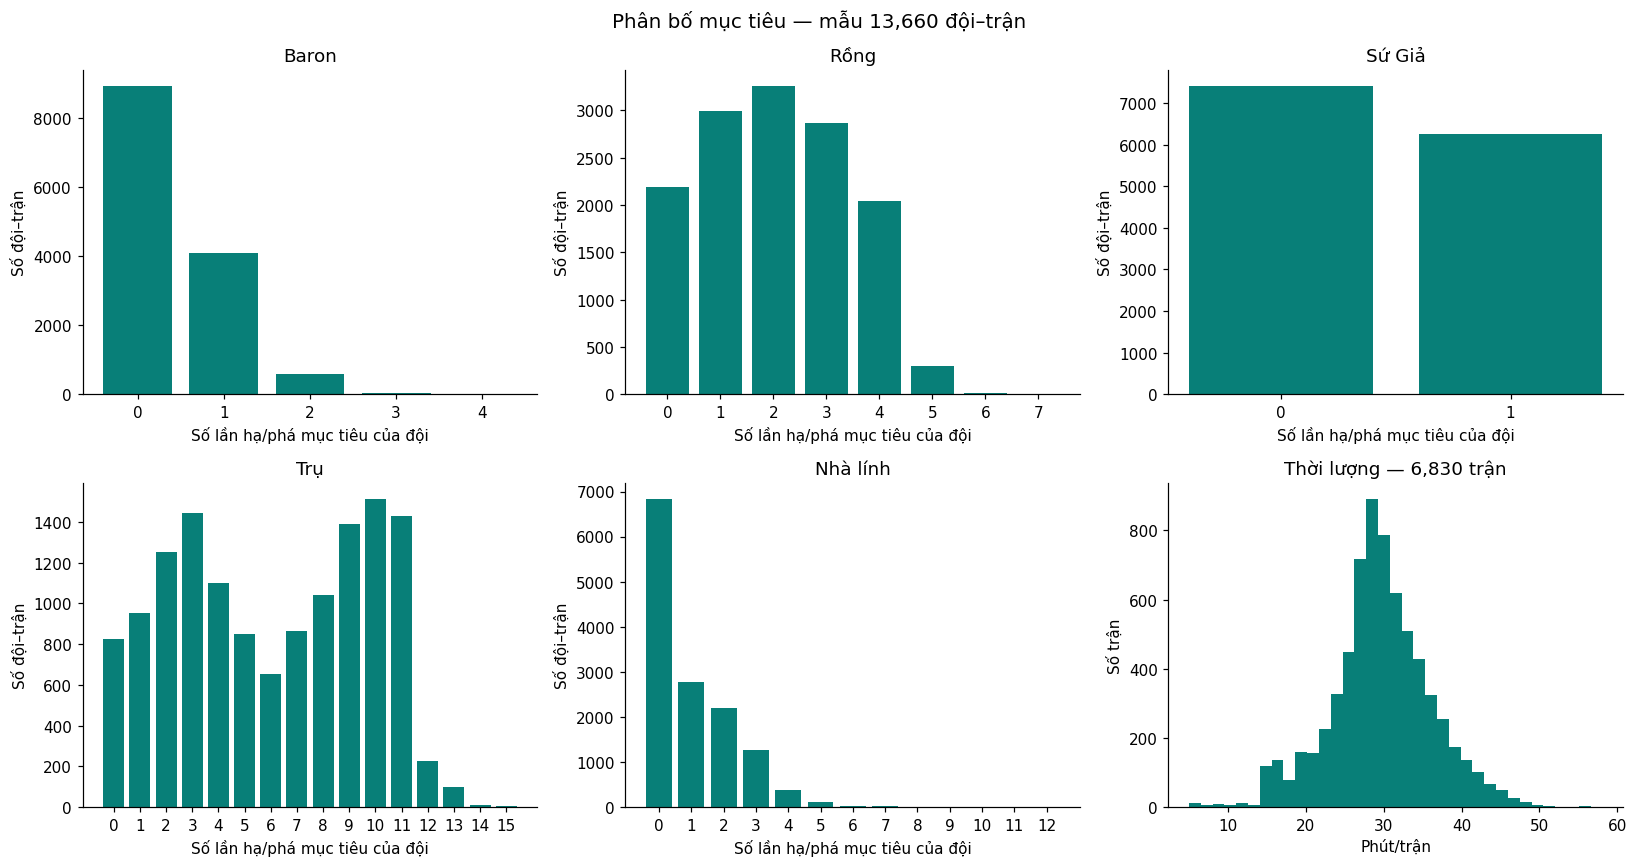

,Tỷ lệ đội không có mục tiêu (%)
Baron,65.37
Rồng,16.04
Sứ Giả,54.28
Trụ,6.05
Nhà lính,50.08


,Thời lượng trận (phút)
Số quan sát,"6,830.00"
Trung bình,29.66
Độ lệch chuẩn,6.53
Nhỏ nhất,5.02
Q1 (25%),26.25
Trung vị (50%),29.50
Q3 (75%),33.50
P95 (95%),40.68
P99 (99%),45.65
Lớn nhất,58.08



**Nhận xét:** 65.37% đội–trận không có Baron;
54.28% không có Sứ Giả.
Thời lượng trung vị là **29.50 phút**, 50% trận nằm trong
26.25–33.50 phút,
toàn khoảng 5.02–58.08 phút.
Không so sánh tổng mục tiêu giữa các trận mà bỏ qua thời lượng.


In [18]:
match_duration = team_df.groupby('game_id')['duration_min'].first()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, objective_cols):
    counts = team_df[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=TEAL)
    ax.set(title=objective_labels[col], xlabel='Số lần hạ/phá mục tiêu của đội', ylabel='Số đội–trận')
    if counts.index.max() <= 15:
        ax.set_xticks(range(int(counts.index.max()) + 1))
axes.flat[5].hist(match_duration, bins=35, color=TEAL)
axes.flat[5].set(title=f'Thời lượng — {n_games:,} trận', xlabel='Phút/trận', ylabel='Số trận')
fig.suptitle(f'Phân bố mục tiêu — mẫu {len(team_df):,} đội–trận', fontsize=13)
plt.tight_layout()
plt.show()
objective_zero_pct = team_df[objective_cols].eq(0).mean() * 100
display(bang_tieng_viet(objective_zero_pct.rename(index=objective_labels).rename('ty_le_doi_khong_co_muc_tieu_pct').to_frame()))
display(bang_tieng_viet(match_duration.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).rename('phut_tran').to_frame()))
display(Markdown(f"""
**Nhận xét:** {objective_zero_pct['team_baronKills']:.2f}% đội–trận không có Baron;
{objective_zero_pct['team_riftHeraldKills']:.2f}% không có Sứ Giả.
Thời lượng trung vị là **{match_duration.median():.2f} phút**, 50% trận nằm trong
{match_duration.quantile(0.25):.2f}–{match_duration.quantile(0.75):.2f} phút,
toàn khoảng {match_duration.min():.2f}–{match_duration.max():.2f} phút.
Không so sánh tổng mục tiêu giữa các trận mà bỏ qua thời lượng.
"""))


### 6.3. So sánh đội thắng và đội thua

Bảng so sánh ở mục 6.1 và biểu đồ dưới đây dùng số mục tiêu trung bình của mỗi nhóm.
Mỗi nhóm gồm một đội trong từng trận: đội thắng hoặc đội thua.
Các chỉ số là thống kê **cả trận**, nên khác biệt có thể vừa là nguyên nhân,
hệ quả hoặc đồng thời đi cùng diễn biến thắng/thua. Đây không phải bằng chứng nhân quả.


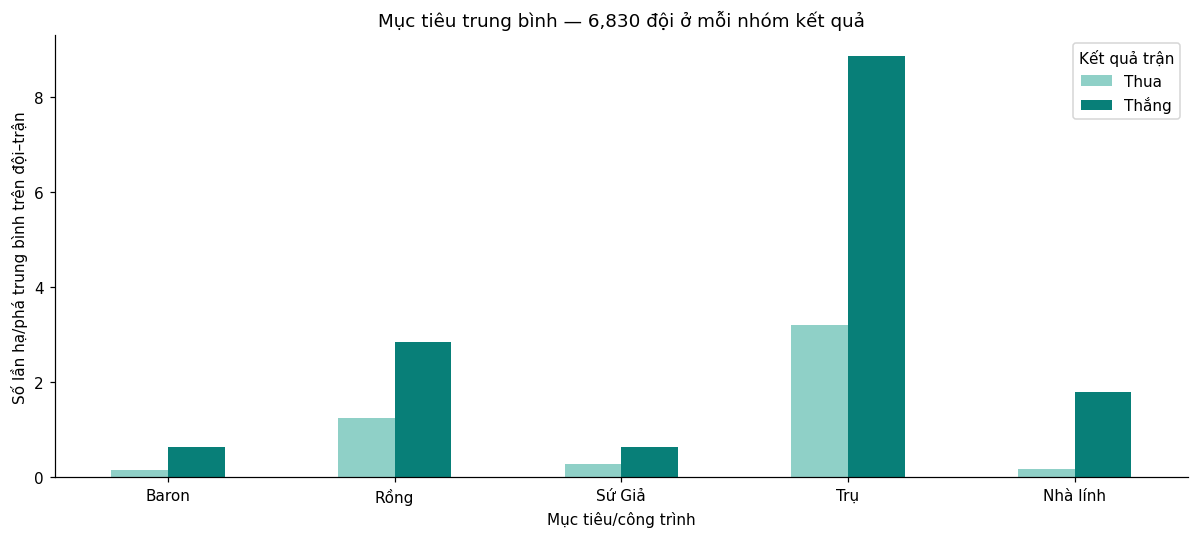


**Nhận xét:** trong mẫu này, trung bình đội thắng có
**8.85 trụ** và
**2.84 rồng**;
đội thua tương ứng 3.21 trụ và
1.24 rồng.
Chênh lệch mô tả rõ ở cấp đội; cần ghép trong cùng trận và xét thời lượng ở các bước sau.


In [19]:
objective_means = team_df.groupby('win')[objective_cols].mean()
objective_plot = objective_means.rename(index={False: 'Thua', True: 'Thắng'}, columns=objective_labels).T
ax = objective_plot.plot(kind='bar', color=[TEAL_LIGHT, TEAL], figsize=(11, 5))
ax.set(title=f'Mục tiêu trung bình — {n_games:,} đội ở mỗi nhóm kết quả',
       xlabel='Mục tiêu/công trình', ylabel='Số lần hạ/phá trung bình trên đội–trận')
ax.legend(title='Kết quả trận')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** trong mẫu này, trung bình đội thắng có
**{objective_means.loc[True, 'team_towerKills']:.2f} trụ** và
**{objective_means.loc[True, 'team_dragonKills']:.2f} rồng**;
đội thua tương ứng {objective_means.loc[False, 'team_towerKills']:.2f} trụ và
{objective_means.loc[False, 'team_dragonKills']:.2f} rồng.
Chênh lệch mô tả rõ ở cấp đội; cần ghép trong cùng trận và xét thời lượng ở các bước sau.
"""))


### 6.4. Chênh lệch hai đội trong cùng trận

Ghép theo `game_id`: chênh lệch = **đội thắng − đội thua**, một dòng mỗi trận.
Biểu đồ trả lời “bao nhiêu phần trăm trận đội thắng có nhiều/bằng/ít hơn?”.
Bảng bổ sung phía dưới trả lời câu khác: “trong nhóm đội có nhiều/bằng/ít hơn
đối thủ, tỷ lệ thắng là bao nhiêu?”. Mẫu số của hai cách đọc khác nhau.


,Số trận,Trung vị chênh lệch,Đội thắng nhiều hơn (%),Bằng nhau (%),Đội thắng ít hơn (%)
Baron,6830,1.00,50.78,42.34,6.88
Rồng,6830,2.00,71.71,14.22,14.07
Sứ Giả,6830,1.00,63.40,8.57,28.04
Trụ,6830,6.00,94.25,3.25,2.50
Nhà lính,6830,2.00,82.23,14.96,2.81


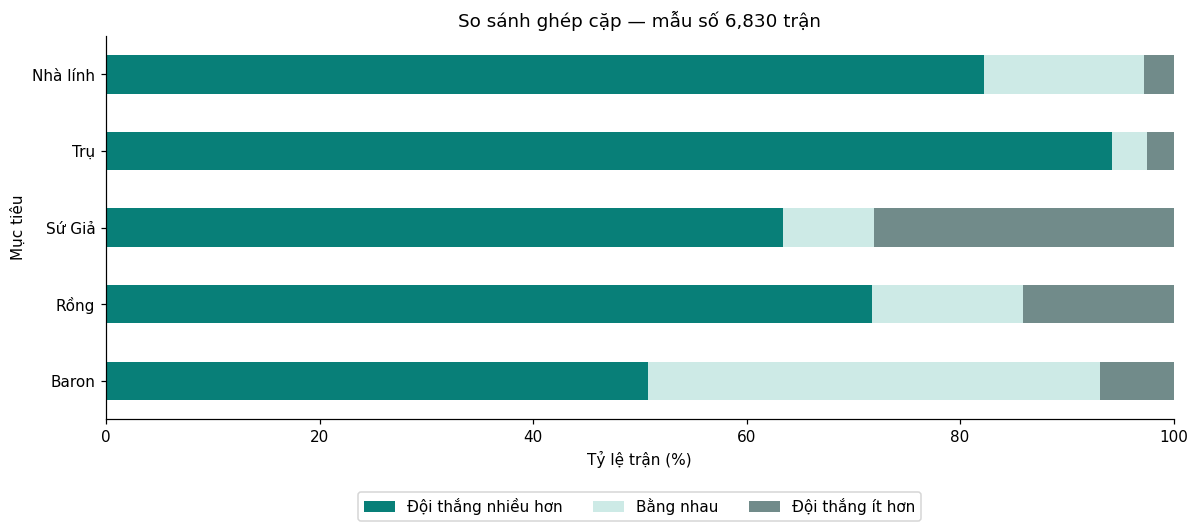

,So sánh với đối thủ,Mục tiêu,Số đội–trận,Số đội thắng,Tỷ lệ thắng (%)
0,Ít hơn,Baron,3938,470,11.93
1,Bằng nhau,Baron,5784,2892,50.00
2,Nhiều hơn,Baron,3938,3468,88.07
3,Ít hơn,Rồng,5859,961,16.40
4,Bằng nhau,Rồng,1942,971,50.00
5,Nhiều hơn,Rồng,5859,4898,83.60
6,Ít hơn,Sứ Giả,6245,1915,30.66
7,Bằng nhau,Sứ Giả,1170,585,50.00
8,Nhiều hơn,Sứ Giả,6245,4330,69.34
9,Ít hơn,Trụ,6608,171,2.59



**Nhận xét:** đội thắng có nhiều trụ hơn ở
**94.25%** số trận;
nhiều rồng hơn ở **71.71%**;
nhiều Baron hơn ở **50.78%**.
Baron bằng nhau ở 42.34% trận,
nên “không hơn Baron” không đồng nghĩa thất bại.
Đây là liên hệ hồi cứu, không phải quy tắc thắng trận hoặc đánh giá khả năng dự đoán trước trận.


In [20]:
winners = team_df.loc[team_df['win']].set_index('game_id').sort_index()
losers = team_df.loc[~team_df['win']].set_index('game_id').sort_index()
assert winners.index.equals(losers.index)
assert np.allclose(winners['duration_min'], losers['duration_min'])
objective_delta = winners[objective_cols] - losers[objective_cols]
objective_delta_summary = pd.DataFrame({
    'so_tran': objective_delta.count(),
    'chenh_lech_trung_vi': objective_delta.median(),
    'thang_nhieu_hon_pct': objective_delta.gt(0).mean() * 100,
    'bang_nhau_pct': objective_delta.eq(0).mean() * 100,
    'thang_it_hon_pct': objective_delta.lt(0).mean() * 100
})
display(bang_tieng_viet(objective_delta_summary.rename(index=objective_labels).round(2)))
delta_plot = objective_delta_summary[['thang_nhieu_hon_pct', 'bang_nhau_pct', 'thang_it_hon_pct']].rename(
    index=objective_labels, columns={
        'thang_nhieu_hon_pct': 'Đội thắng nhiều hơn', 'bang_nhau_pct': 'Bằng nhau',
        'thang_it_hon_pct': 'Đội thắng ít hơn'
    }
)
ax = delta_plot.plot(kind='barh', stacked=True, color=[TEAL, '#CDEAE6', '#718B8A'], figsize=(11, 5))
ax.set(title=f'So sánh ghép cặp — mẫu số {n_games:,} trận', xlabel='Tỷ lệ trận (%)', ylabel='Mục tiêu', xlim=(0, 100))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3)
plt.tight_layout()
plt.show()

# Mỗi trận đóng góp hai đội vào bảng tỷ lệ thắng theo lợi thế; không phải mẫu độc lập.
advantage_tables = []
for col in objective_cols:
    current = team_df[['game_id', 'win', col]].copy()
    # Tổng của hai đội trong trận trừ giá trị đội hiện tại là giá trị đối thủ.
    opponent_value = current.groupby('game_id')[col].transform('sum') - current[col]
    current['so_sanh'] = np.select(
        [current[col].gt(opponent_value), current[col].lt(opponent_value)],
        ['Nhiều hơn', 'Ít hơn'], default='Bằng nhau'
    )
    summary = current.groupby('so_sanh').agg(
        so_doi_tran=('win', 'size'), so_thang=('win', 'sum'), ty_le_thang=('win', 'mean')
    ).reindex(['Ít hơn', 'Bằng nhau', 'Nhiều hơn'])
    summary['ty_le_thang_pct'] = summary.pop('ty_le_thang') * 100
    summary.insert(0, 'muc_tieu', objective_labels[col])
    advantage_tables.append(summary.reset_index())
advantage_summary = pd.concat(advantage_tables, ignore_index=True)
display(bang_tieng_viet(advantage_summary.round(2)))
display(Markdown(f"""
**Nhận xét:** đội thắng có nhiều trụ hơn ở
**{objective_delta_summary.loc['team_towerKills', 'thang_nhieu_hon_pct']:.2f}%** số trận;
nhiều rồng hơn ở **{objective_delta_summary.loc['team_dragonKills', 'thang_nhieu_hon_pct']:.2f}%**;
nhiều Baron hơn ở **{objective_delta_summary.loc['team_baronKills', 'thang_nhieu_hon_pct']:.2f}%**.
Baron bằng nhau ở {objective_delta_summary.loc['team_baronKills', 'bang_nhau_pct']:.2f}% trận,
nên “không hơn Baron” không đồng nghĩa thất bại.
Đây là liên hệ hồi cứu, không phải quy tắc thắng trận hoặc đánh giá khả năng dự đoán trước trận.
"""))


### 6.5. Mục tiêu theo thời lượng

Chia nhóm thời lượng `[0,20)`, `[20,25)`, `[25,30)`, `[30,35)`, `[35,+∞)` phút.
Công bố số trận từng nhóm, so sánh riêng thắng/thua. Bổ sung chỉ số trên 10 phút
để tham khảo; đây là phép chia trên **toàn thời lượng**, không phải thời gian mục tiêu
có thể xuất hiện hoặc số mục tiêu ở phút thứ 10. Ghép cặp ở mục 6.4 đã giữ hai đội
trong cùng trận nên chúng có chung thời lượng.


,Số trận
Thời lượng (phút),
<20,521
20–<25,799
25–<30,2351
30–<35,1893
≥35,1266


,Nhóm thời lượng (phút),Nhóm đội,Số Baron trung bình/đội,Số rồng trung bình/đội,Số Sứ Giả trung bình/đội,Số trụ phá trung bình/đội,Số lần phá nhà lính trung bình/đội
0,<20,Thua,0.00,0.36,0.01,0.29,0.00
1,<20,Thắng,0.00,1.47,0.31,3.61,0.25
2,20–<25,Thua,0.00,0.61,0.09,1.29,0.00
3,20–<25,Thắng,0.00,2.33,0.86,8.13,1.33
4,25–<30,Thua,0.02,0.94,0.24,2.63,0.03
5,25–<30,Thắng,0.56,2.84,0.73,9.31,1.85
6,30–<35,Thua,0.14,1.45,0.37,3.88,0.13
7,30–<35,Thắng,0.82,3.06,0.60,9.48,1.97
8,≥35,Thua,0.55,2.25,0.46,5.68,0.73
9,≥35,Thắng,1.22,3.38,0.50,9.65,2.38


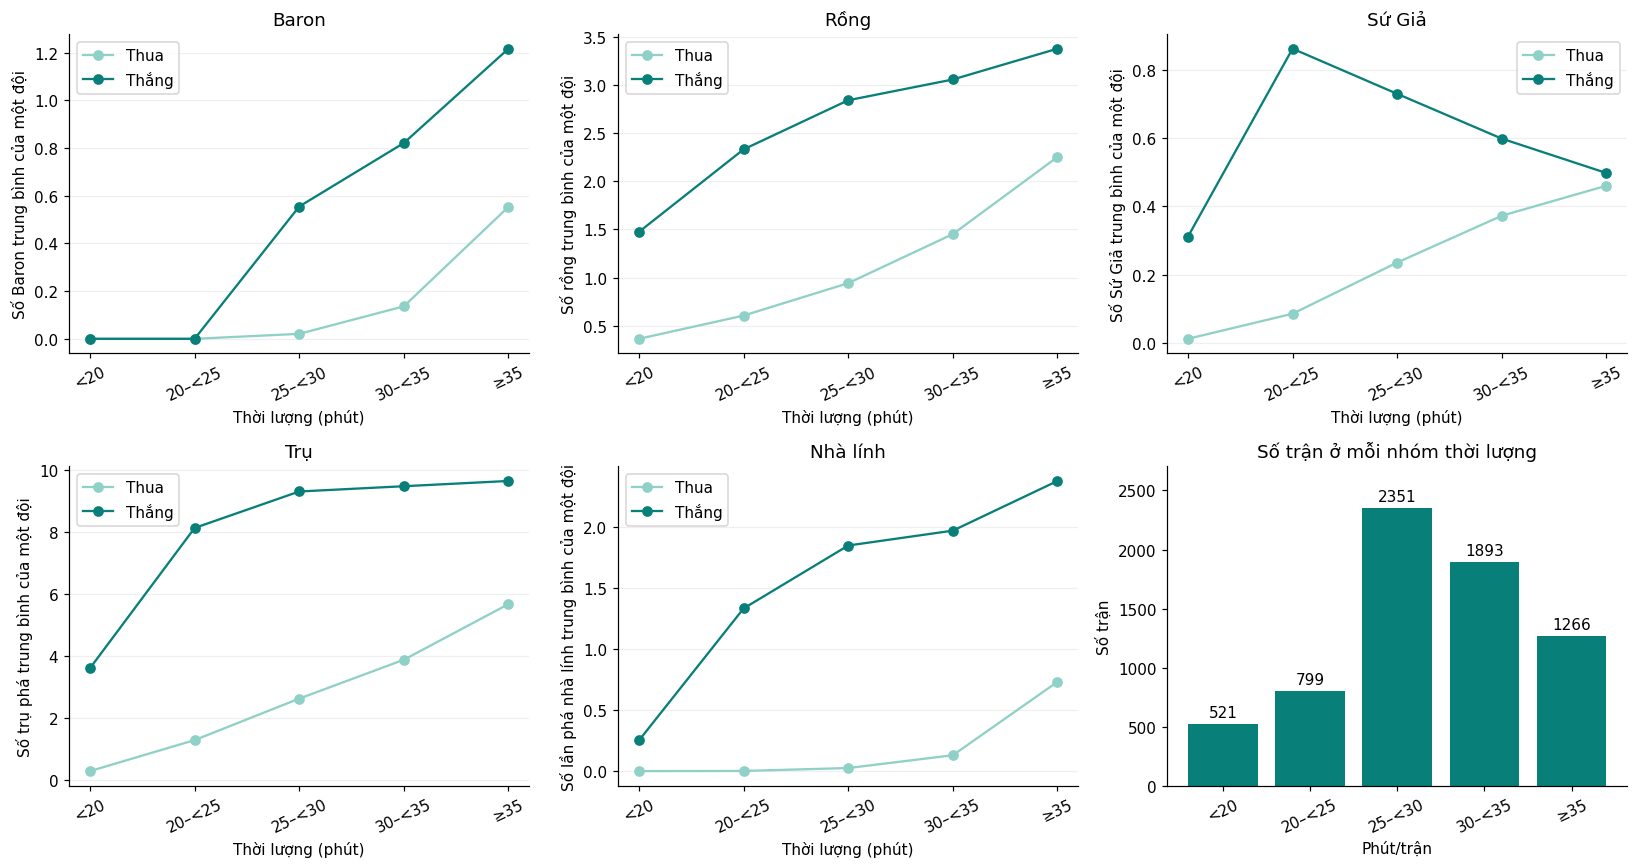

,Baron,Rồng,Sứ Giả,Trụ,Nhà lính
Nhóm đội,,,,,
Thua,0.04,0.39,0.09,1.00,0.05
Thắng,0.20,0.96,0.22,3.00,0.59



**Nhận xét:** nhóm thời lượng nhiều trận nhất là
**25–<30 phút**, có 2,351 trận.
Các đường trung bình cho thấy số mục tiêu phụ thuộc cả kết quả và nhóm thời lượng;
không gộp chúng thành tác động riêng của một mục tiêu.
Nhóm ít trận nhất chỉ có 521 trận, cần thận trọng khi đối chiếu.
Các trận rất ngắn vẫn được giữ và được nhìn riêng ở nhóm dưới 20 phút.


In [21]:
duration_labels = ['<20', '20–<25', '25–<30', '30–<35', '≥35']
duration_edges = [0, 20, 25, 30, 35, np.inf]
team_df['duration_group'] = pd.cut(team_df['duration_min'], bins=duration_edges, labels=duration_labels, right=False)
duration_group_counts = pd.cut(match_duration, bins=duration_edges, labels=duration_labels, right=False).value_counts(sort=False)
display(bang_tieng_viet(duration_group_counts.rename('so_tran').to_frame()))
objective_duration_means = team_df.groupby(['duration_group', 'win'], observed=True)[objective_cols].mean()
# Đưa hai chỉ mục nhóm thành cột để mọi tên cột cùng nằm trên một hàng.
objective_duration_table = objective_duration_means.reset_index().rename(columns={
    'team_baronKills': 'Số Baron trung bình/đội',
    'team_dragonKills': 'Số rồng trung bình/đội',
    'team_riftHeraldKills': 'Số Sứ Giả trung bình/đội',
    'team_towerKills': 'Số trụ phá trung bình/đội',
    'team_inhibitorKills': 'Số lần phá nhà lính trung bình/đội',
})
display(bang_tieng_viet(objective_duration_table.round(2)))
objective_ylabels = {
    'team_baronKills': 'Số Baron trung bình của một đội',
    'team_dragonKills': 'Số rồng trung bình của một đội',
    'team_riftHeraldKills': 'Số Sứ Giả trung bình của một đội',
    'team_towerKills': 'Số trụ phá trung bình của một đội',
    'team_inhibitorKills': 'Số lần phá nhà lính trung bình của một đội',
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, objective_cols):
    for outcome, color, label in [(False, TEAL_LIGHT, 'Thua'), (True, TEAL, 'Thắng')]:
        values = objective_duration_means.xs(outcome, level='win')[col].reindex(duration_labels)
        ax.plot(range(len(duration_labels)), values, marker='o', color=color, label=label)
    ax.set_xticks(range(len(duration_labels)), duration_labels, rotation=25)
    ax.set(title=objective_labels[col], xlabel='Thời lượng (phút)', ylabel=objective_ylabels[col])
    ax.grid(axis='y', alpha=0.2)
    ax.legend()
axes.flat[5].bar(duration_labels, duration_group_counts, color=TEAL)
axes.flat[5].bar_label(axes.flat[5].containers[0], padding=3)
axes.flat[5].set(title='Số trận ở mỗi nhóm thời lượng', xlabel='Phút/trận', ylabel='Số trận')
axes.flat[5].tick_params(axis='x', rotation=25)
axes.flat[5].set_ylim(0, duration_group_counts.max() * 1.15)
plt.tight_layout()
plt.show()

objective_per10 = team_df[objective_cols].div(team_df['duration_min'], axis=0) * 10
objective_per10['win'] = team_df['win']
display(bang_tieng_viet(objective_per10.groupby('win')[objective_cols].mean().rename(
    index={False: 'Thua', True: 'Thắng'}, columns=objective_labels
).round(3)))
display(Markdown(f"""
**Nhận xét:** nhóm thời lượng nhiều trận nhất là
**{duration_group_counts.idxmax()} phút**, có {duration_group_counts.max():,} trận.
Các đường trung bình cho thấy số mục tiêu phụ thuộc cả kết quả và nhóm thời lượng;
không gộp chúng thành tác động riêng của một mục tiêu.
Nhóm ít trận nhất chỉ có {duration_group_counts.min():,} trận, cần thận trọng khi đối chiếu.
Các trận rất ngắn vẫn được giữ và được nhìn riêng ở nhóm dưới 20 phút.
"""))


## 7. Kết hợp chọn lọc các nhóm

### 7.1. Điểm Mastery theo Rank và vị trí

Dùng trung vị, Q1–Q3 và boxplot có cả nhóm 0. Rank chỉ giữ lượt đủ bậc/đoàn;
vị trí chỉ giữ nhãn hợp lệ. Hai mẫu được công bố riêng, không mặc định giống nhau.
Thang `symlog` giữ 0 và đuôi dài. Số lượt hiển thị kèm mỗi nhóm.


,Số lượt,Trung vị,Q1 (25%),Q3 (75%),Tỷ lệ điểm bằng 0 (%)
Bậc Rank Solo/Duo,,,,,
IRON,15,"15,896.00","3,232.00","39,506.00",13.33
BRONZE,310,"27,072.50","8,548.00","95,995.50",0.97
SILVER,2354,"44,072.50","13,988.25","129,397.75",3.61
GOLD,10022,"52,205.00","16,566.50","154,597.25",4.75
PLATINUM,16480,"66,745.00","23,621.75","203,664.00",0.87
EMERALD,23974,"85,000.50","29,125.50","256,623.00",0.18
DIAMOND,9667,"111,211.00","38,009.00","331,607.50",0.01
MASTER,3491,"150,120.00","45,739.00","470,561.00",0.03
GRANDMASTER,897,"177,398.00","50,820.00","504,936.00",0.00


,Số lượt,Trung vị,Q1 (25%),Q3 (75%),Tỷ lệ điểm bằng 0 (%)
Vị trí,,,,,
TOP,13661,"65,317.00","22,691.00","220,162.00",1.20
JUNGLE,13743,"72,619.00","25,692.00","227,779.50",1.19
MIDDLE,13654,"68,991.00","21,618.25","243,331.00",1.15
BOTTOM,13666,"99,808.00","36,876.50","250,854.00",1.02
SUPPORT,13576,"82,018.50","26,370.00","260,180.75",1.08


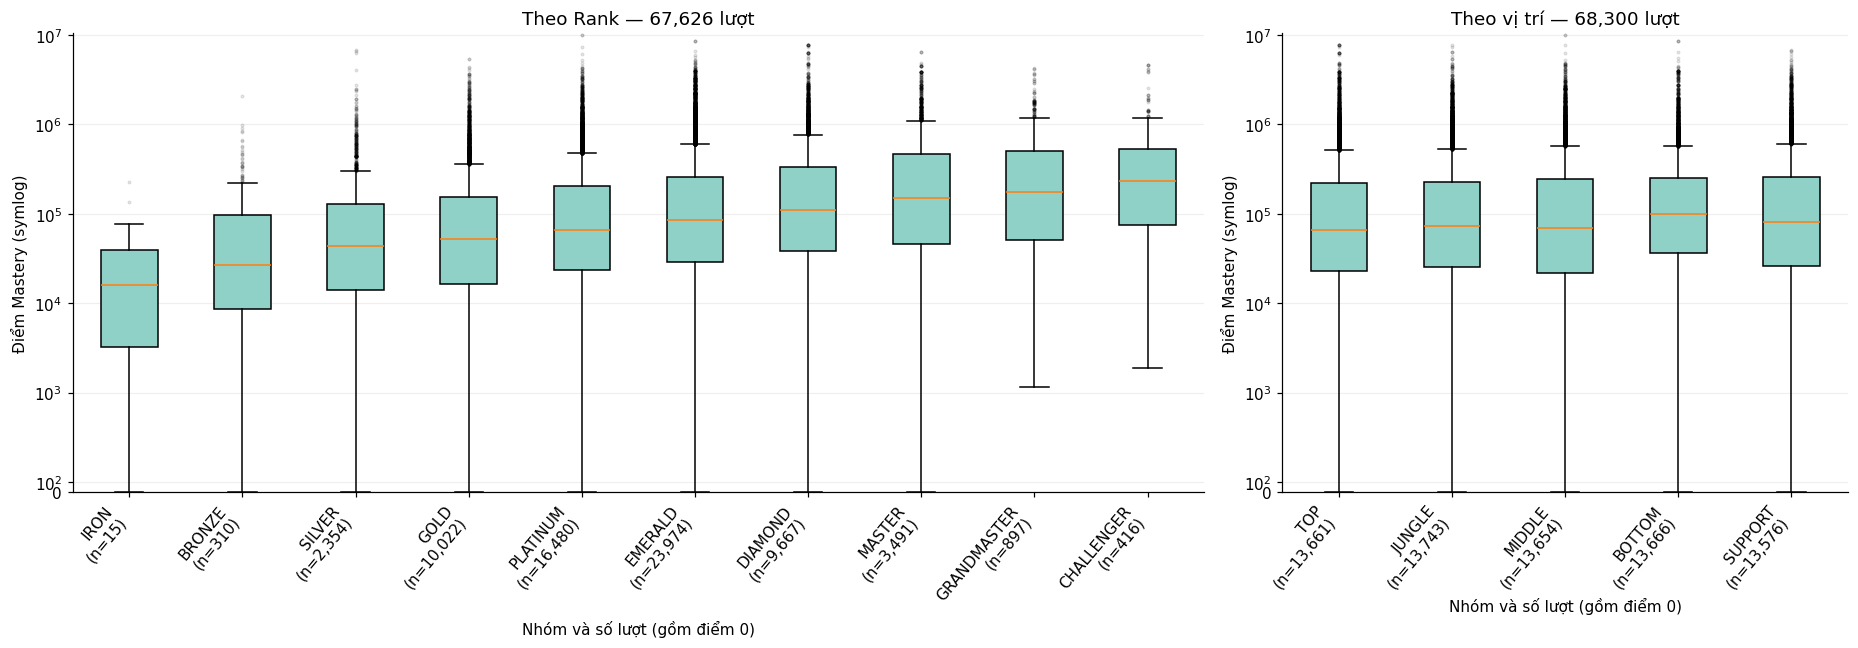


**Nhận xét:** trung vị Mastery từ Gold **52,205**
đến Emerald **85,000.5** và Diamond
**111,211** tăng theo bậc trong mẫu này.
Theo vị trí, trung vị BOTTOM là
**99,808**, TOP là
**65,317.0**.
Các nhóm còn khác về tướng, tài khoản lặp và thời điểm ghi nhận; chưa thể kết luận
chơi nhiều một tướng làm tăng rank hoặc một vị trí đòi hỏi Mastery cao hơn.


In [22]:
mastery_rank_df = eda_df.loc[~rank_missing_mask].copy()
mastery_rank_summary = mastery_rank_df.groupby('solo_tier').agg(
    so_luot=('mastery_points', 'size'), trung_vi=('mastery_points', 'median'),
    q25=('mastery_points', lambda s: s.quantile(0.25)),
    q75=('mastery_points', lambda s: s.quantile(0.75)),
    ty_le_diem_0_pct=('mastery_points', lambda s: s.eq(0).mean() * 100)
).reindex(tier_order_all)
mastery_position_summary = position_valid_df.groupby('position').agg(
    so_luot=('mastery_points', 'size'), trung_vi=('mastery_points', 'median'),
    q25=('mastery_points', lambda s: s.quantile(0.25)),
    q75=('mastery_points', lambda s: s.quantile(0.75)),
    ty_le_diem_0_pct=('mastery_points', lambda s: s.eq(0).mean() * 100)
).reindex(position_order)
display(bang_tieng_viet(mastery_rank_summary.round(2)))
display(bang_tieng_viet(mastery_position_summary.round(2)))
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [2, 1]})
for ax, data, group_col, groups, title in [
    (axes[0], mastery_rank_df, 'solo_tier', tier_order_all, f'Theo Rank — {len(mastery_rank_df):,} lượt'),
    (axes[1], position_valid_df, 'position', position_order, f'Theo vị trí — {len(position_valid_df):,} lượt')
]:
    present = [g for g in groups if data[group_col].eq(g).any()]
    grouped_values = [data.loc[data[group_col].eq(g), 'mastery_points'] for g in present]
    boxes = ax.boxplot(grouped_values, patch_artist=True, flierprops={'markersize': 1.5, 'alpha': 0.15})
    for box in boxes['boxes']:
        box.set_facecolor(TEAL_LIGHT)
    ax.set_xticks(range(1, len(present) + 1), [f'{g}\n(n={len(v):,})' for g, v in zip(present, grouped_values)], rotation=50, ha='right')
    ax.set_yscale('symlog', linthresh=1000)
    ax.set_ylim(bottom=0)
    ax.set(title=title, xlabel='Nhóm và số lượt (gồm điểm 0)', ylabel='Điểm Mastery (symlog)')
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** trung vị Mastery từ Gold **{mastery_rank_summary.loc['GOLD', 'trung_vi']:,.0f}**
đến Emerald **{mastery_rank_summary.loc['EMERALD', 'trung_vi']:,.1f}** và Diamond
**{mastery_rank_summary.loc['DIAMOND', 'trung_vi']:,.0f}** tăng theo bậc trong mẫu này.
Theo vị trí, trung vị BOTTOM là
**{mastery_position_summary.loc['BOTTOM', 'trung_vi']:,.0f}**, TOP là
**{mastery_position_summary.loc['TOP', 'trung_vi']:,.1f}**.
Các nhóm còn khác về tướng, tài khoản lặp và thời điểm ghi nhận; chưa thể kết luận
chơi nhiều một tướng làm tăng rank hoặc một vị trí đòi hỏi Mastery cao hơn.
"""))


### 7.2. Cơ cấu tướng theo Rank

Chỉ vẽ bậc có **ít nhất 200 lượt đủ rank**, để tránh đưa Iron (rất ít lượt) vào
heatmap đông ô; đây là ngưỡng trình bày thăm dò, không phải đảm bảo độ tin cậy.
Chọn 10 tướng nhiều lượt nhất toàn mẫu để dễ đọc. Mỗi ô là phần trăm trên **tất cả
lượt đủ rank của bậc đó**, gồm cả các tướng không hiển thị. Vì vậy hàng không cộng
thành 100%. Bảng tướng đứng đầu từng bậc được tính trên toàn bộ tướng.


,Số lượt của bậc,Tướng phổ biến nhất,Số lượt của tướng đứng đầu,Tỷ trọng tướng đứng đầu (%)
Bậc Rank Solo/Duo,,,,
BRONZE,310,Yone,11,3.55
SILVER,2354,Lux,60,2.55
GOLD,10022,Jinx,212,2.12
PLATINUM,16480,Jinx,419,2.54
EMERALD,23974,Jinx,617,2.57
DIAMOND,9667,Jinx,232,2.40
MASTER,3491,Karma,87,2.49
GRANDMASTER,897,Karma,23,2.56
CHALLENGER,416,Karma,28,6.73


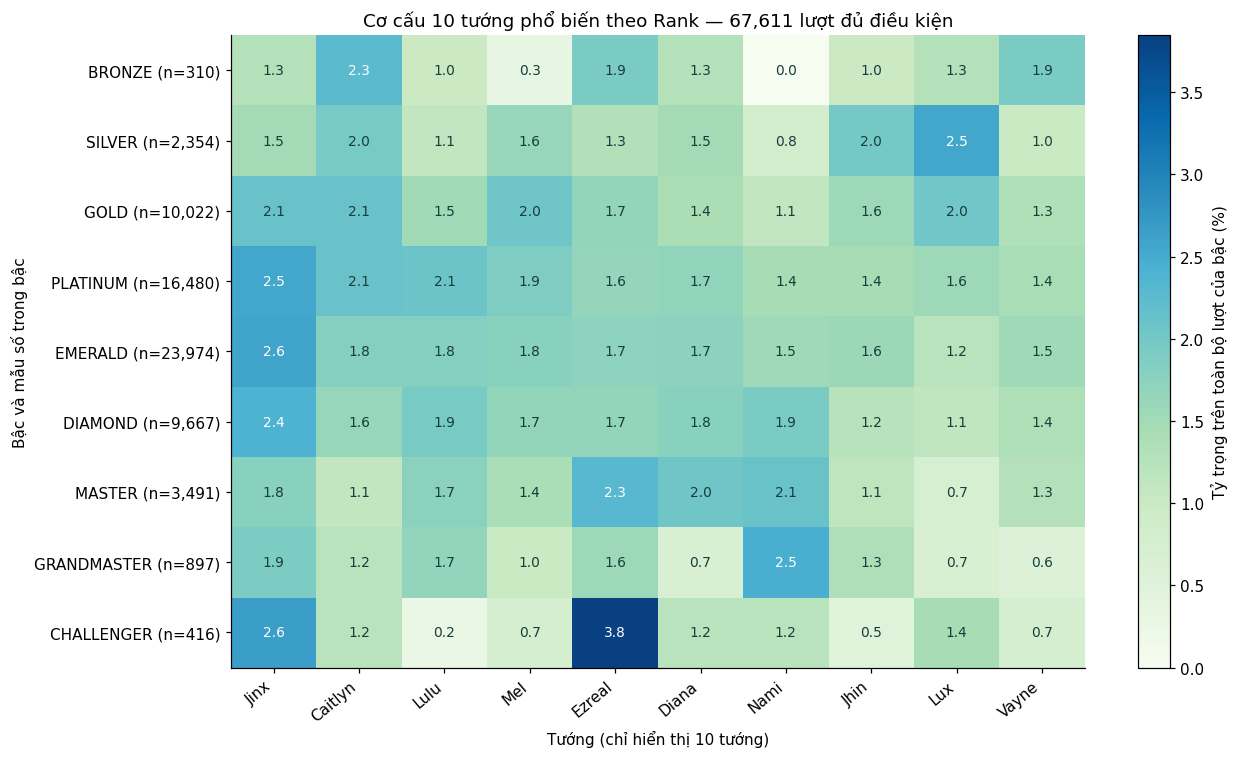


**Nhận xét:** mẫu biểu đồ giữ **67,611/68,300 lượt**,
gồm 9 bậc có ít nhất 200 lượt đủ thông tin.
Tướng đứng đầu ở Gold là **Jinx**
(2.12%),
ở Master là **Karma**
(2.49%).
Cơ cấu có thể khác theo bậc nhưng cũng phụ thuộc vị trí và phiên bản;
không gọi tỷ trọng này là tỷ lệ thắng hoặc kết luận tướng nào mạnh hơn.


In [23]:
champion_rank_counts = pd.crosstab(mastery_rank_df['solo_tier'], mastery_rank_df['champion_name'])
rank_sample_sizes = champion_rank_counts.sum(axis=1).reindex(tier_order_all, fill_value=0)
min_rank_sample = 200
eligible_tiers = rank_sample_sizes[rank_sample_sizes.ge(min_rank_sample)].index.tolist()
champion_rank_sample_size = int(rank_sample_sizes.reindex(eligible_tiers).sum())
champion_rank_pct = champion_rank_counts.div(champion_rank_counts.sum(axis=1), axis=0) * 100
top10_champions = champion_summary.head(10).index.tolist()
champion_rank_heat = champion_rank_pct.reindex(index=eligible_tiers, columns=top10_champions, fill_value=0)
leading_champions_by_rank = pd.DataFrame({
    'so_luot_cua_bac': rank_sample_sizes.reindex(eligible_tiers),
    'tuong_nhieu_luot_nhat': champion_rank_counts.reindex(eligible_tiers).idxmax(axis=1),
    'so_luot_tuong_dung_dau': champion_rank_counts.reindex(eligible_tiers).max(axis=1),
    'ty_trong_tuong_dung_dau_pct': champion_rank_pct.reindex(eligible_tiers).max(axis=1)
})
display(bang_tieng_viet(leading_champions_by_rank.round(2)))
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(champion_rank_heat, cmap='GnBu', aspect='auto', vmin=0)
ax.set_xticks(range(len(top10_champions)), top10_champions, rotation=40, ha='right')
ax.set_yticks(range(len(eligible_tiers)), [f'{t} (n={rank_sample_sizes[t]:,})' for t in eligible_tiers])
for i in range(len(eligible_tiers)):
    for j in range(len(top10_champions)):
        value = champion_rank_heat.iloc[i, j]
        ax.text(j, i, f'{value:.1f}', ha='center', va='center', fontsize=9,
                color='white' if value > champion_rank_heat.to_numpy().max() * 0.55 else '#163E3B')
fig.colorbar(im, ax=ax, label='Tỷ trọng trên toàn bộ lượt của bậc (%)')
ax.set(title=f'Cơ cấu 10 tướng phổ biến theo Rank — {champion_rank_sample_size:,} lượt đủ điều kiện',
       xlabel='Tướng (chỉ hiển thị 10 tướng)', ylabel='Bậc và mẫu số trong bậc')
plt.tight_layout()
plt.show()
display(Markdown(f"""
**Nhận xét:** mẫu biểu đồ giữ **{champion_rank_sample_size:,}/{n_rows:,} lượt**,
gồm {len(eligible_tiers)} bậc có ít nhất {min_rank_sample} lượt đủ thông tin.
Tướng đứng đầu ở Gold là **{leading_champions_by_rank.loc['GOLD', 'tuong_nhieu_luot_nhat']}**
({leading_champions_by_rank.loc['GOLD', 'ty_trong_tuong_dung_dau_pct']:.2f}%),
ở Master là **{leading_champions_by_rank.loc['MASTER', 'tuong_nhieu_luot_nhat']}**
({leading_champions_by_rank.loc['MASTER', 'ty_trong_tuong_dung_dau_pct']:.2f}%).
Cơ cấu có thể khác theo bậc nhưng cũng phụ thuộc vị trí và phiên bản;
không gọi tỷ trọng này là tỷ lệ thắng hoặc kết luận tướng nào mạnh hơn.
"""))


## 8. Tổng hợp phát hiện và câu hỏi phân tích tiếp theo

Các nhận xét dưới đây được tạo lại từ kết quả đang chạy, không lấy số liệu cố định
từ bản bàn giao. Chúng gợi ý hướng phân tích, chưa phải giả thuyết bắt buộc phải đúng.


In [24]:
bottom_median = mastery_position_summary.loc['BOTTOM', 'trung_vi']
top_median = mastery_position_summary.loc['TOP', 'trung_vi']
tower_more_pct = objective_delta_summary.loc['team_towerKills', 'thang_nhieu_hon_pct']
dragon_more_pct = objective_delta_summary.loc['team_dragonKills', 'thang_nhieu_hon_pct']
summary_md = f"""
# Tóm tắt EDA — League of Legends Season 15 (EUN)

- **Quy mô:** {n_rows:,} lượt, {n_games:,} trận, {len(team_df):,} đội–trận;
  không có khóa tài khoản bền vững. Các trận được ghi nhận từ
  {eda_df['start_datetime'].min():%d/%m/%Y} đến {eda_df['start_datetime'].max():%d/%m/%Y} UTC.
- **Rank:** {top_two_tiers.index[0]} và {top_two_tiers.index[1]} chiếm
  {top_two_tiers.sum() / n_rows * 100:.2f}% số lượt. Có {rank_missing_mask.sum():,}
  lượt thiếu bậc/đoàn; không đưa các số tài khoản 0 đi kèm vào thống kê theo rank.
- **Số trận tài khoản theo Rank:** trung vị được ghi nhận là
  {rank_activity_summary.loc['GOLD', 'trung_vi']:.0f} ở Gold,
  {rank_activity_summary.loc['DIAMOND', 'trung_vi']:.0f} ở Diamond và
  {rank_activity_summary.loc['MASTER', 'trung_vi']:.0f} ở Master.
  Đây là thống kê theo lượt, không phải số trận cần để đạt Rank hay số trận của CSV.
- **Mastery:** trung bình {points.mean():,.0f}, trung vị {points.median():,.0f},
  P99 {points.quantile(0.99):,.0f}, lớn nhất {points.max():,}. Có
  {mastery_all_zero_mask.sum():,} lượt mà cả 6 trường Mastery bằng 0;
  giữ nguyên vì chưa rõ ý nghĩa. Phân bố lệch phải, phù hợp dùng phân vị và thang log.
- **Vị trí:** đã sửa {len(position_corrections)} nhãn Invalid trong bảng phân tích:
  Yuumi và Lulu thành SUPPORT, Volibear thành TOP sau khi đối chiếu cùng đội.
  Dữ liệu gốc có {raw_invalid_position_count} lượt Invalid; sau sửa còn {len(invalid_rows)}
  lượt không có nhãn hợp lệ. Có {(~team_role_ok).sum():,} đội–trận không có đúng một
  lượt ở mỗi vị trí chuẩn. Các phép kết hợp theo vị trí dùng {len(position_valid_df):,} lượt.
- **Tướng:** {len(champion_summary)} tướng; {top_champion_name} nhiều nhất với
  {champion_summary.iloc[0]['so_luot']:,.0f} lượt. Mã–tên một-một.
- **Thời điểm ghi nhận:** {mastery_after_match_pct:.2f}% trong {time_valid.sum():,}
  lượt có timestamp Mastery dương nằm sau thời điểm kết thúc trận nếu đọc là epoch ms;
  chưa dùng Mastery làm dữ liệu trước trận. Bản build nhiều trận nhất là
  {version_summary.index[0]} ({version_summary.iloc[0]['ty_trong_tran_pct']:.2f}% số trận).
- **Mối liên hệ:** Mastery trung vị BOTTOM {bottom_median:,.0f} so với TOP
  {top_median:,.1f}; Mastery trung vị tăng theo bậc ở các nhóm quan sát được.
  Đội thắng nhiều trụ hơn trong {tower_more_pct:.2f}% trận, nhiều rồng hơn trong
  {dragon_more_pct:.2f}% trận. Đây đều là liên hệ mô tả.

## Ba câu hỏi có thể lựa chọn

| Câu hỏi | Dữ liệu và cách phân tích dự kiến | Giới hạn cần giữ |
|---|---|---|
| Mastery có liên hệ với tỷ lệ thắng trong CSV, và khác nhau theo Rank/vị trí không? | Dùng `mastery_points`, `mastery_level`, `win`, `solo_tier`, `position`, `champion_name`, `game_id`; chia nhóm điểm theo phân vị, công bố số lượt từng nhóm; xem riêng nhóm 0 và đối chiếu trong cùng Rank/vị trí/tướng. | Chưa biết thời điểm ghi nhận Mastery; có nhiều timestamp sau trận; lượt có thể lặp tài khoản, phụ thuộc cùng trận. Không kết luận nhân quả hoặc xem đây là dự báo trước trận. |
| Cơ cấu tướng có khác theo Rank khi cùng vị trí và phiên bản không? | Dùng `champion_name`, `solo_tier`, `position`, `game_version`, `game_id`; so sánh tỷ trọng trong cùng Rank–vị trí–phiên bản, giữ số quan sát và giảm số nhóm khi mẫu quá nhỏ. | Rank không cân bằng, không có lượt cấm hoặc cách chọn mẫu; độ phổ biến không tương đương sức mạnh; phiên bản ít trận có thể không đủ để so sánh. |
| Chênh lệch rồng/Baron/trụ liên hệ với thắng/thua thế nào trong các nhóm thời lượng? | Dùng bảng đội–trận từ `game_id` + `win`, 5 chỉ số mục tiêu, `duration`; ghép hai đội và so sánh theo thời lượng; công bố cả trường hợp bằng nhau. | Chỉ số là tổng cuối trận, thiếu thời điểm chiếm mục tiêu; kết quả và thời lượng có thể cùng phụ thuộc diễn biến trận. Cần xác minh các số đếm công trình cực trị. |

## Quyết định xử lý và điều còn chưa chắc chắn

- Giữ CSV, giữ các ngoại lệ và số 0. Chỉ loại `flex_tier`/`flex_rank` khỏi bảng khám phá;
  ba cột số Flex vẫn có trong `df_kham_pha` và `eda_df`.
- UNKNOWN chỉ là nhãn hiển thị. Không dùng hàng toàn 0 để diễn giải cơ cấu đoàn.
- Ba nhãn vị trí Invalid được sửa theo chỉ định của người làm bài và đối chiếu
  vị trí còn thiếu trong cùng đội; giữ bảng ghi lại thay đổi và không sửa CSV gốc.
- Chưa xác minh nguyên nhân thiếu rank, nhóm Mastery toàn 0, các cơ cấu vị trí còn
  không chuẩn, thời điểm snapshot Rank/Mastery và định nghĩa đếm công trình.
- Chưa biết quy trình lấy mẫu hoặc số tài khoản duy nhất. Kết quả chỉ mô tả mẫu EUN này;
  không đại diện toàn cộng đồng. Không làm kiểm định trên các lượt như thể độc lập.
- Chưa huấn luyện mô hình. Nếu đi tiếp, cần xác định thời điểm có sẵn của biến và
  xử lý phụ thuộc theo trận trước khi kiểm định hoặc chia dữ liệu.
"""
display(Markdown(summary_md))
Path('artifacts').mkdir(exist_ok=True)
Path('artifacts/Tom_tat_EDA.md').write_text(summary_md.strip() + '\n', encoding='utf-8')


Out[24]: 3944



# Tóm tắt EDA — League of Legends Season 15 (EUN)

- **Quy mô:** 68,300 lượt, 6,830 trận, 13,660 đội–trận;
  không có khóa tài khoản bền vững. Các trận được ghi nhận từ
  10/01/2025 đến 20/02/2025 UTC.
- **Rank:** EMERALD và PLATINUM chiếm
  59.23% số lượt. Có 674
  lượt thiếu bậc/đoàn; không đưa các số tài khoản 0 đi kèm vào thống kê theo rank.
- **Số trận tài khoản theo Rank:** trung vị được ghi nhận là
  75 ở Gold,
  113 ở Diamond và
  130 ở Master.
  Đây là thống kê theo lượt, không phải số trận cần để đạt Rank hay số trận của CSV.
- **Mastery:** trung bình 240,148, trung vị 77,603,
  P99 2,247,914, lớn nhất 10,024,014. Có
  771 lượt mà cả 6 trường Mastery bằng 0;
  giữ nguyên vì chưa rõ ý nghĩa. Phân bố lệch phải, phù hợp dùng phân vị và thang log.
- **Vị trí:** đã sửa 3 nhãn Invalid trong bảng phân tích:
  Yuumi và Lulu thành SUPPORT, Volibear thành TOP sau khi đối chiếu cùng đội.
  Dữ liệu gốc có 3 lượt Invalid; sau sửa còn 0
  lượt không có nhãn hợp lệ. Có 126 đội–trận không có đúng một
  lượt ở mỗi vị trí chuẩn. Các phép kết hợp theo vị trí dùng 68,300 lượt.
- **Tướng:** 170 tướng; Jinx nhiều nhất với
  1,624 lượt. Mã–tên một-một.
- **Thời điểm ghi nhận:** 99.19% trong 67,529
  lượt có timestamp Mastery dương nằm sau thời điểm kết thúc trận nếu đọc là epoch ms;
  chưa dùng Mastery làm dữ liệu trước trận. Bản build nhiều trận nhất là
  15.3.656.4086 (82.28% số trận).
- **Mối liên hệ:** Mastery trung vị BOTTOM 99,808 so với TOP
  65,317.0; Mastery trung vị tăng theo bậc ở các nhóm quan sát được.
  Đội thắng nhiều trụ hơn trong 94.25% trận, nhiều rồng hơn trong
  71.71% trận. Đây đều là liên hệ mô tả.

## Ba câu hỏi có thể lựa chọn

| Câu hỏi | Dữ liệu và cách phân tích dự kiến | Giới hạn cần giữ |
|---|---|---|
| Mastery có liên hệ với tỷ lệ thắng trong CSV, và khác nhau theo Rank/vị trí không? | Dùng `mastery_points`, `mastery_level`, `win`, `solo_tier`, `position`, `champion_name`, `game_id`; chia nhóm điểm theo phân vị, công bố số lượt từng nhóm; xem riêng nhóm 0 và đối chiếu trong cùng Rank/vị trí/tướng. | Chưa biết thời điểm ghi nhận Mastery; có nhiều timestamp sau trận; lượt có thể lặp tài khoản, phụ thuộc cùng trận. Không kết luận nhân quả hoặc xem đây là dự báo trước trận. |
| Cơ cấu tướng có khác theo Rank khi cùng vị trí và phiên bản không? | Dùng `champion_name`, `solo_tier`, `position`, `game_version`, `game_id`; so sánh tỷ trọng trong cùng Rank–vị trí–phiên bản, giữ số quan sát và giảm số nhóm khi mẫu quá nhỏ. | Rank không cân bằng, không có lượt cấm hoặc cách chọn mẫu; độ phổ biến không tương đương sức mạnh; phiên bản ít trận có thể không đủ để so sánh. |
| Chênh lệch rồng/Baron/trụ liên hệ với thắng/thua thế nào trong các nhóm thời lượng? | Dùng bảng đội–trận từ `game_id` + `win`, 5 chỉ số mục tiêu, `duration`; ghép hai đội và so sánh theo thời lượng; công bố cả trường hợp bằng nhau. | Chỉ số là tổng cuối trận, thiếu thời điểm chiếm mục tiêu; kết quả và thời lượng có thể cùng phụ thuộc diễn biến trận. Cần xác minh các số đếm công trình cực trị. |

## Quyết định xử lý và điều còn chưa chắc chắn

- Giữ CSV, giữ các ngoại lệ và số 0. Chỉ loại `flex_tier`/`flex_rank` khỏi bảng khám phá;
  ba cột số Flex vẫn có trong `df_kham_pha` và `eda_df`.
- UNKNOWN chỉ là nhãn hiển thị. Không dùng hàng toàn 0 để diễn giải cơ cấu đoàn.
- Ba nhãn vị trí Invalid được sửa theo chỉ định của người làm bài và đối chiếu
  vị trí còn thiếu trong cùng đội; giữ bảng ghi lại thay đổi và không sửa CSV gốc.
- Chưa xác minh nguyên nhân thiếu rank, nhóm Mastery toàn 0, các cơ cấu vị trí còn
  không chuẩn, thời điểm snapshot Rank/Mastery và định nghĩa đếm công trình.
- Chưa biết quy trình lấy mẫu hoặc số tài khoản duy nhất. Kết quả chỉ mô tả mẫu EUN này;
  không đại diện toàn cộng đồng. Không làm kiểm định trên các lượt như thể độc lập.
- Chưa huấn luyện mô hình. Nếu đi tiếp, cần xác định thời điểm có sẵn của biến và
  xử lý phụ thuộc theo trận trước khi kiểm định hoặc chia dữ liệu.


## 9. Kiểm tra hoàn tất và xuất bảng

Kiểm tra các tổng và đơn vị quan sát trước khi lưu bảng đầy đủ vào `artifacts/tables/`.
CSV xuất dùng UTF-8 có BOM để mở tiếng Việt bằng Excel. Các bảng xuất là dẫn xuất;
CSV trong `data/` vẫn nguyên vẹn. Notebook phải chạy tuần tự từ đầu để có đầy đủ biến.


In [25]:
verification_results = {
    'raw_rows': int(len(df_raw)), 'raw_columns': int(df_raw.shape[1]),
    'games': int(n_games), 'team_rows': int(len(team_df)),
    'original_selection_columns': int(df.shape[1]),
    'exploration_columns': int(df_kham_pha.shape[1]),
    'full_duplicate_rows': duplicate_rows,
    'duplicate_participant_keys': int(df_raw.duplicated(['game_id', 'participant_id']).sum()),
    'all_games_have_10_rows': bool(game_sizes.eq(10).all()),
    'all_teams_have_5_rows': bool(team_sizes.eq(5).all()),
    'rank_distribution_sums_to_rows': bool(tier_counts.sum() == n_rows),
    'division_rows_are_iron_to_diamond': bool(set(division_pct.index).issubset(tier_order_divisions)),
    'division_rows_sum_to_100': bool(np.allclose(division_pct.sum(axis=1), 100)),
    'all_numeric_flex_columns_retained': bool(set(['flex_lp', 'flex_wins', 'flex_losses']).issubset(df_kham_pha.columns)),
    'champion_mapping_one_to_one': bool(id_to_name.eq(1).all() and name_to_id.eq(1).all()),
    'champion_counts_sum_to_rows': bool(champion_summary['so_luot'].sum() == n_rows),
    'champion_position_rows_sum_to_100': bool(np.allclose(champion_position_pct.sum(axis=1), 100)),
    'team_objectives_constant': bool(team_consistency.eq(1).all().all()),
    'two_team_rows_per_game': bool(len(team_df) == 2 * n_games),
    'paired_deltas_equal_game_count': bool(len(objective_delta) == n_games),
    'objective_totals_not_repeated': bool(np.allclose(eda_df[objective_cols].sum(), 5 * team_df[objective_cols].sum())),
    'duration_groups_cover_all_games': bool(duration_group_counts.sum() == n_games),
    'duration_unit_seconds_checked': bool(duration_is_seconds),
    'source_csv_unchanged': bool(hashlib.sha256(csv_path.read_bytes()).hexdigest() == csv_sha256),
    'rank_missing_rows': int(rank_missing_mask.sum()),
    'all_zero_mastery_rows': int(mastery_all_zero_mask.sum()),
    'invalid_position_rows': int(len(invalid_rows)),
    'raw_invalid_position_rows': raw_invalid_position_count,
    'corrected_position_rows': int(len(position_corrections)),
    'position_corrections_exactly_three': bool(eda_df['position'].ne(df_raw['position']).sum() == 3),
    'teams_without_one_of_each_position': int((~team_role_ok).sum()),
}
for name, value in verification_results.items():
    if isinstance(value, bool):
        assert value, f'Kiểm tra thất bại: {name}'
display(bang_tieng_viet(pd.Series(verification_results, name='ket_qua').to_frame()))

table_dir = Path('artifacts/tables')
table_dir.mkdir(parents=True, exist_ok=True)
tables = {
    'chat_luong_chung': quality_summary, 'phien_ban_so_tran': version_summary,
    'rank_phan_bo': tier_summary,
    'rank_doan_so_dem': division_counts, 'rank_doan_ty_le': division_pct,
    'rank_tong_tran_tai_khoan': rank_activity_summary, 'rank_thong_ke_tai_khoan': account_by_tier,
    'mastery_chat_luong': mastery_quality, 'mastery_phan_vi': mastery_summary,
    'vi_tri_phan_bo': position_summary, 'vi_tri_khong_hop_le': invalid_rows,
    'vi_tri_da_sua': position_corrections,
    'vi_tri_co_cau_doi_can_kiem_tra': team_role_counts.loc[~team_role_ok],
    'tuong_day_du': champion_summary, 'tuong_vi_tri_so_dem': champion_position_counts,
    'tuong_vi_tri_ty_le': champion_position_pct,
    'muc_tieu_doi_tran': team_df, 'muc_tieu_chenh_lech_tung_tran': objective_delta,
    'muc_tieu_so_sanh_thang_thua': objective_comparison,
    'muc_tieu_chenh_lech_tom_tat': objective_delta_summary,
    'muc_tieu_ty_le_thang_theo_loi_the': advantage_summary,
    'muc_tieu_theo_thoi_luong': objective_duration_table.set_index(['duration_group', 'win']),
    'mastery_theo_rank': mastery_rank_summary, 'mastery_theo_vi_tri': mastery_position_summary,
    'tuong_dung_dau_theo_rank': leading_champions_by_rank,
    'tuong_theo_rank_ty_le_day_du': champion_rank_pct,
}
for name, table in tables.items():
    bang_tieng_viet(table).to_csv(table_dir / f'{name}.csv', encoding='utf-8-sig', index=True)
print(f'Đã lưu {len(tables)} bảng vào {table_dir.resolve()} và bản tóm tắt artifacts/Tom_tat_EDA.md.')


Đã lưu 26 bảng vào C:\Users\phat\Downloads\Đồ án KHDL\artifacts\tables và bản tóm tắt artifacts/Tom_tat_EDA.md.


,Kết quả
Số dòng dữ liệu gốc,68300
Số cột dữ liệu gốc,69
Số trận,6830
Số đội–trận,13660
Số cột chọn ban đầu,24
Số cột khám phá,22
Số dòng trùng hoàn toàn,0
Số khóa người chơi–trận bị trùng,0
Mọi trận đều có 10 lượt,True
Mọi đội đều có 5 lượt,True


### Nguồn tham khảo và khả năng tái lập

- Nguồn tính toán: CSV cục bộ `data/League of Legends Ranked Match Data  Season 15 (EUN).csv`.
- Hai tài liệu Riot về khái niệm rank:
  [Ranked Tiers, Divisions, and Queues](https://support.riotgames.com/en-us/league-of-legends/gameplay/ranked-tiers-divisions-and-queues)
  và [Master, Grandmaster, and Challenger: The Apex Tiers](https://support.riotgames.com/en-us/league-of-legends/gameplay/master-grandmaster-and-challenger-the-apex-tiers).
  Trang đang phục vụ được đối chiếu ngày **07/11/2026**, hiển thị ngày cập nhật
  tháng 5/2026. Đây là nguồn giải thích khái niệm, **không** là bằng chứng về mọi
  quy tắc trong giai đoạn tháng 1–2/2025 của CSV. Nhận xét cơ cấu đoàn bên trên dựa trên
  giá trị quan sát; không áp ngưỡng lên hạng, giới hạn token hoặc cơ chế Mastery hiện tại
  để sửa dữ liệu lịch sử.
- Bản notebook trước khi sửa: `artifacts/main_truoc_EDA.ipynb`.
- Môi trường: Python 3.12; thư viện trong `requirements.txt`. Xem `README.md` để chạy.
- Các nhận xét kết quả được hiển thị từ code bằng `Markdown(...)` để số liệu thay đổi
  cùng dữ liệu khi chạy lại. Không cần truy cập mạng khi thực thi notebook.
